# Explainable AI-Based Clinical Decision Support System for Diabetes
### Case study: predicting Type 2 Diabetes patient readmission within 30 days of discharge

**Dataset:** Diabetes 130-US Hospitals (UCI Machine Learning Repository), file `diabetic_data.csv`  
**Target:** class 1 = readmitted within 30 days, class 0 = not readmitted within 30 days

**How to run:** `Runtime > Run all`. When the upload button appears, choose `diabetic_data.csv`.
The slowest steps are cross-validation (Section 10) and hyperparameter tuning (Section 12).

| # | Section | # | Section |
|---|---|---|---|
| 1 | Setup | 12 | Hyperparameter tuning |
| 2 | Dataset upload and loading | 13 | Probability calibration |
| 3 | Dataset inspection | 14 | Threshold optimization |
| 4 | Data cleaning and target | 15 | Save artifacts |
| 5 | Feature engineering | 16 | SHAP (global and local) |
| 6 | Exploratory data analysis | 17 | LIME (local) |
| 7 | Train-test split, scaling, SMOTE | 18 | SHAP vs LIME |
| 8 | Model training | 19 | LLM natural-language explanation |
| 9 | Model evaluation | 20 | Clinical decision support function |
| 10 | Cross-validation | 21 | New patient prediction |
| 11 | Best model selection | 22-23 | Streamlit app and deployment |

**Corrections made to the earlier notebook** (details are explained in each section):
1. `None` in `max_glu_serum` / `A1Cresult` means "test not done". Pandas was silently reading it as missing, and mode imputation then turned 95% of patients into "Norm" / ">8". Fixed.
2. Imputation values and label encoders are now learned from the training split only.
3. Diabetes severity rule matched only the exact code `250`, so `250.01`, `250.83` ... scored 0. Fixed to cover all `250.xx`.
4. Hyperparameter tuning ran on already-SMOTEd data (synthetic copies leaked across folds, giving an unrealistic CV ROC-AUC of 0.96). Scaling and SMOTE are now inside the CV pipeline.
5. Calibration was fitted on SMOTE-balanced data, so probabilities were not on the real-world scale. It is now calibrated on real, un-resampled training folds.
6. The decision threshold was tuned on the test set. It is now chosen from out-of-fold training predictions; the test set is used once, for the final report.
7. The best model is chosen from cross-validation, not from test-set scores.
8. SHAP-vs-LIME sign agreement was computed over all 51 features including zeros. It now uses the shared top features.
9. New: SHAP waterfall/force plots, LLM explanation with safe fallback, CDSS function, Streamlit app and deployment bundle. EBM is not used.

## 1. Setup
Installs the libraries that are not guaranteed to be in Colab, then imports everything.

In [1]:
!pip -q install imbalanced-learn xgboost lime google-genai
!pip -q install -U shap

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import os, sys, glob, json, time, shutil, warnings, importlib, platform

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn, imblearn, xgboost, shap
from IPython.display import display, Markdown

from sklearn.base import clone
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_validate,
                                     cross_val_predict, RandomizedSearchCV)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, brier_score_loss,
                             classification_report, confusion_matrix, roc_curve,
                             precision_recall_curve)
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)

RANDOM_STATE = 42
CLASS_LABELS = ["Not readmitted <30d", "Readmitted <30d"]

print("Python", platform.python_version(), "| scikit-learn", sklearn.__version__,
      "| imbalanced-learn", imblearn.__version__, "| xgboost", xgboost.__version__,
      "| shap", shap.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)

Python 3.13.18 | scikit-learn 1.6.1 | imbalanced-learn 0.14.2 | xgboost 3.4.1 | shap 0.54.1 | pandas 2.2.3 | numpy 2.4.6


## 2. Dataset upload and loading
If `diabetic_data.csv` is not already in the Colab session, an upload button appears.

`keep_default_na=False` is important: by default pandas treats the text `None` as a missing value,
but in this dataset `None` in `max_glu_serum` and `A1Cresult` is a real category ("test not measured").
The dataset marks true missing values with `?`, which is handled in Section 4.

In [3]:
DATA_PATH = "diabetic_data.csv"

if not os.path.exists(DATA_PATH):
    found = sorted(glob.glob("*diabetic_data*.csv"))
    if found:
        DATA_PATH = found[0]
    else:
        from google.colab import files
        print("Please upload diabetic_data.csv")
        uploaded = files.upload()
        DATA_PATH = next(iter(uploaded))

raw_df = pd.read_csv(DATA_PATH, keep_default_na=False)
raw_df.columns = raw_df.columns.str.strip()

required = {"readmitted", "diag_1", "diag_2", "diag_3", "number_inpatient", "num_medications"}
missing_cols = required - set(raw_df.columns)
assert not missing_cols, f"This is not the Diabetes 130-US Hospitals file. Missing columns: {missing_cols}"
print("Loaded", DATA_PATH, "->", raw_df.shape)

Please upload diabetic_data.csv


Saving diabetic_data.csv to diabetic_data.csv
Loaded diabetic_data.csv -> (101766, 50)


## 3. Dataset inspection
Look at the real structure of the data before writing any preprocessing code.

In [4]:
print("Shape (rows, columns):", raw_df.shape)
display(raw_df.head())

Shape (rows, columns): (101766, 50)


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,?,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,?,?,1,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,?,?,59,0,18,0,0,0,276,250.01,255,9,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,?,?,11,5,13,2,0,1,648,250,V27,6,None,None,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,?,?,44,1,16,0,0,0,8,250.43,403,7,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,?,?,51,0,8,0,0,0,197,157,250,5,None,None,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [5]:
print("Column names:\n", list(raw_df.columns))
print("\nData types:")
print(raw_df.dtypes.to_string())

Column names:
 ['encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'weight', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'payer_code', 'medical_specialty', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1', 'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted']

Data types:
encounter_id                 int64
patient_nbr                  int64
race                        object
gender                      object
age           

In [6]:
print("Statistical summary - numerical columns")
display(raw_df.describe().T)
print("Statistical summary - categorical columns")
display(raw_df.select_dtypes(exclude="number").describe().T)

Statistical summary - numerical columns


,count,mean,std,min,25%,50%,75%,max
encounter_id,101766.0,1.652016e+08,1.026403e+08,12522.0,84961194.0,152388987.0,2.302709e+08,443867222.0
patient_nbr,101766.0,5.433040e+07,3.869636e+07,135.0,23413221.0,45505143.0,8.754595e+07,189502619.0
admission_type_id,101766.0,2.024006e+00,1.445403e+00,1.0,1.0,1.0,3.000000e+00,8.0
discharge_disposition_id,101766.0,3.715642e+00,5.280166e+00,1.0,1.0,1.0,4.000000e+00,28.0
admission_source_id,101766.0,5.754437e+00,4.064081e+00,1.0,1.0,7.0,7.000000e+00,25.0
time_in_hospital,101766.0,4.395987e+00,2.985108e+00,1.0,2.0,4.0,6.000000e+00,14.0
num_lab_procedures,101766.0,4.309564e+01,1.967436e+01,1.0,31.0,44.0,5.700000e+01,132.0
num_procedures,101766.0,1.339730e+00,1.705807e+00,0.0,0.0,1.0,2.000000e+00,6.0
num_medications,101766.0,1.602184e+01,8.127566e+00,1.0,10.0,15.0,2.000000e+01,81.0
number_outpatient,101766.0,3.693572e-01,1.267265e+00,0.0,0.0,0.0,0.000000e+00,42.0


Statistical summary - categorical columns


,count,unique,top,freq
race,101766,6,Caucasian,76099
gender,101766,3,Female,54708
age,101766,10,[70-80),26068
weight,101766,10,?,98569
payer_code,101766,18,?,40256
medical_specialty,101766,73,?,49949
diag_1,101766,717,428,6862
diag_2,101766,749,276,6752
diag_3,101766,790,250,11555
max_glu_serum,101766,4,None,96420


In [7]:
TARGET = "readmitted"
print("Target variable:", TARGET)
print("\nReadmission class distribution (original 3 classes):")
display(pd.DataFrame({"count": raw_df[TARGET].value_counts(),
                      "percent": (raw_df[TARGET].value_counts(normalize=True) * 100).round(2)}))

missing_table = pd.DataFrame({"missing ('?')": (raw_df == "?").sum()})
missing_table["percent"] = (missing_table["missing ('?')"] / len(raw_df) * 100).round(2)
missing_table = missing_table[missing_table["missing ('?')"] > 0].sort_values("percent", ascending=False)
print("Missing values (the dataset marks them with '?'):")
display(missing_table)

print("Fully duplicated rows:", int(raw_df.duplicated().sum()))
print("'None' (= test not measured) in max_glu_serum: %d | in A1Cresult: %d"
      % ((raw_df["max_glu_serum"] == "None").sum(), (raw_df["A1Cresult"] == "None").sum()))

Target variable: readmitted

Readmission class distribution (original 3 classes):


,count,percent
readmitted,,
NO,54864,53.91
>30,35545,34.93
<30,11357,11.16


Missing values (the dataset marks them with '?'):


,missing ('?'),percent
weight,98569,96.86
medical_specialty,49949,49.08
payer_code,40256,39.56
race,2273,2.23
diag_3,1423,1.40
diag_2,358,0.35
diag_1,21,0.02


Fully duplicated rows: 0
'None' (= test not measured) in max_glu_serum: 96420 | in A1Cresult: 84748


## 4. Data cleaning and target variable

**A. Missing values.** `?` is replaced by NaN. Categorical gaps are filled with the mode and
numerical gaps with the median - but those values are *learned from the training split only*
(Section 7) so that nothing from the test set leaks into training.

**B. Column elimination.** `encounter_id` and `patient_nbr` are identifiers (no predictive meaning,
and a privacy risk). `weight` is about 97% missing. `payer_code` and `medical_specialty` are about 40-49%
missing and administrative.

**C. Binary target.** `<30` -> 1, `>30` -> 0, `NO` -> 0. The clinical and policy question is
specifically early readmission (within 30 days), which is the standard hospital quality indicator.
A readmission after 30 days is treated the same as no readmission for this question, so a binary
classifier matches the decision the system has to support.

**D. Encoding** is done with `LabelEncoder`, fitted on the training split in Section 7.

In [8]:
df = raw_df.replace("?", np.nan)

cols_to_drop = ["encounter_id", "patient_nbr", "weight", "payer_code", "medical_specialty"]
df = df.drop(columns=cols_to_drop, errors="ignore")

before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print("Duplicate rows removed:", before - len(df))

df[TARGET] = (df[TARGET] == "<30").astype(int)      # <30 -> 1 ; >30 and NO -> 0

print("Shape after cleaning:", df.shape)
print("\nBinary target distribution:")
display(pd.DataFrame({"count": df[TARGET].value_counts(),
                      "percent": (df[TARGET].value_counts(normalize=True) * 100).round(2)}))
print("Remaining missing values per column:")
display(df.isna().sum()[df.isna().sum() > 0].to_frame("missing"))

Duplicate rows removed: 0
Shape after cleaning: (101766, 45)

Binary target distribution:


,count,percent
readmitted,,
0,90409,88.84
1,11357,11.16


Remaining missing values per column:


,missing
race,2273
diag_1,21
diag_2,358
diag_3,1423


## 5. Feature engineering
The preprocessing code lives in one small module, `cdss_utils.py`, written by the next cell.
The notebook, SHAP, LIME, the new-patient section and the Streamlit app all import the *same*
functions, so training and deployment can never use different preprocessing.

| Feature | Formula | Why it helps |
|---|---|---|
| `previous_admissions` | `number_inpatient + number_emergency` | Patients with recent acute hospital use are the ones most often readmitted |
| `medication_load` | `num_medications` | Proxy for treatment complexity (note: identical to `num_medications`, kept to match the project design) |
| `time_since_last_visit` | `outpatient*30 + inpatient*60 + emergency*15` | A weighted healthcare-utilisation score (it is a proxy, not a real number of days) |
| `diag_1_num`, `diag_2_num`, `diag_3_num` | ICD-9 code as a number; `V`/`E` codes and blanks -> 0 | Lets tree models split on diagnosis ranges |
| `diag_severity` | circulatory 390-459 = 3, diabetes 250.xx = 3, respiratory 460-519 = 2, digestive 520-579 = 2, injury 800-999 = 1, other = 0; summed over the three diagnoses | Summarises how serious the combination of diagnoses is |

In [9]:
%%writefile cdss_utils.py
"""cdss_utils.py - shared preprocessing for the Diabetes Readmission CDSS.

The SAME functions are used for training, testing, SHAP, LIME, new-patient
inference and the Streamlit app, so preprocessing can never drift apart.
"""
import numpy as np
import pandas as pd
from sklearn.preprocessing import LabelEncoder

TARGET = "readmitted"
DROP_COLS = ["encounter_id", "patient_nbr", "weight", "payer_code", "medical_specialty"]
DIAG_COLS = ["diag_1", "diag_2", "diag_3"]
ENGINEERED_COLS = ["previous_admissions", "medication_load", "time_since_last_visit",
                   "diag_1_num", "diag_2_num", "diag_3_num", "diag_severity"]
MISSING_TOKENS = ["?", ""]   # NOTE: the text "None" is a real category (test not done), not missing


def safe_float(x):
    """Convert an ICD-9 code to a number. V/E codes, blanks and bad input -> 0.0."""
    try:
        v = float(x)
    except (TypeError, ValueError):
        return 0.0
    return v if np.isfinite(v) else 0.0


def severity_score(code):
    """Rule-based severity of one ICD-9 diagnosis code."""
    if 390 <= code < 460:
        return 3          # circulatory diseases (390-459)
    if 460 <= code < 520:
        return 2          # respiratory diseases (460-519)
    if 520 <= code < 580:
        return 2          # digestive diseases (520-579)
    if 250 <= code < 251:
        return 3          # diabetes (250.xx)
    if 800 <= code < 1000:
        return 1          # injuries (800-999)
    return 0


def add_engineered_features(df):
    """Row-wise feature engineering (no statistics are learned, so no leakage)."""
    out = df.copy()
    for c in ["number_inpatient", "number_emergency", "number_outpatient", "num_medications"]:
        out[c] = pd.to_numeric(out[c], errors="coerce").fillna(0)
    out["previous_admissions"] = out["number_inpatient"] + out["number_emergency"]
    out["medication_load"] = out["num_medications"]
    out["time_since_last_visit"] = (out["number_outpatient"] * 30
                                    + out["number_inpatient"] * 60
                                    + out["number_emergency"] * 15)
    for c in DIAG_COLS:
        out[c + "_num"] = out[c].apply(safe_float)
    out["diag_severity"] = sum(out[c + "_num"].apply(severity_score) for c in DIAG_COLS)
    return out


def fit_preprocessor(X_train):
    """Learn imputation values and label encoders from the TRAINING data only."""
    X = X_train.replace(MISSING_TOKENS, np.nan)
    cat_cols = [c for c in X.columns if not pd.api.types.is_numeric_dtype(X[c])]
    num_cols = [c for c in X.columns if c not in cat_cols]
    impute = {}
    for c in cat_cols:
        impute[c] = str(X[c].dropna().astype(str).mode().iloc[0])     # mode
    for c in num_cols:
        impute[c] = float(X[c].median())                              # median
    state = {"raw_columns": list(X.columns), "categorical_cols": cat_cols,
             "numeric_cols": num_cols, "impute_values": impute}
    X = add_engineered_features(_clean_and_impute(X, state))
    encoders = {}
    for c in cat_cols:
        encoders[c] = LabelEncoder().fit(X[c].astype(str))
    state["label_encoders"] = encoders
    state["feature_columns"] = list(X.columns)
    return state


def _clean_and_impute(df, state):
    X = pd.DataFrame(df).copy()
    for c in state["raw_columns"]:
        if c not in X.columns:
            X[c] = np.nan
    X = X[state["raw_columns"]].replace(MISSING_TOKENS, np.nan)
    for c in state["numeric_cols"]:
        X[c] = pd.to_numeric(X[c], errors="coerce").fillna(state["impute_values"][c])
    for c in state["categorical_cols"]:
        col = X[c].astype(object)
        col = col.where(col.notna(), state["impute_values"][c])
        X[c] = col.astype(str).str.strip()
    return X


def transform_features(df, state, return_unseen=False):
    """Raw patient rows -> model-ready numeric matrix (same columns, same order as training).

    Categories never seen in training are replaced by the most frequent training
    category of that column (and reported when return_unseen=True)."""
    X = add_engineered_features(_clean_and_impute(df, state))
    unseen = {}
    for c in state["categorical_cols"]:
        classes = state["label_encoders"][c].classes_
        mapping = {v: i for i, v in enumerate(classes)}
        codes = X[c].map(mapping)
        bad = codes.isna()
        if bad.any():
            unseen[c] = sorted(set(X.loc[bad, c]))
            codes = codes.fillna(mapping[state["impute_values"][c]])
        X[c] = codes.astype(int)
    X = X[state["feature_columns"]].astype(float)
    return (X, unseen) if return_unseen else X


def decode_features(row_enc, state):
    """Encoded row -> {feature: human-readable value} (categories back to their labels)."""
    out = {}
    for f, v in zip(state["feature_columns"], np.asarray(row_enc, dtype=float)):
        if f in state["label_encoders"]:
            classes = state["label_encoders"][f].classes_
            i = int(round(v))
            out[f] = str(classes[i]) if 0 <= i < len(classes) else "unknown"
        else:
            out[f] = int(v) if float(v).is_integer() else round(float(v), 2)
    return out

Writing cdss_utils.py


In [10]:
import cdss_utils
importlib.reload(cdss_utils)
from cdss_utils import (add_engineered_features, fit_preprocessor, transform_features,
                        decode_features, ENGINEERED_COLS)

eda = add_engineered_features(df)        # copy used only for EDA
print("Engineered features added:", ENGINEERED_COLS)
display(eda[["number_inpatient", "number_emergency", "number_outpatient", "num_medications",
             "diag_1", "diag_2", "diag_3"] + ENGINEERED_COLS].head())

Engineered features added: ['previous_admissions', 'medication_load', 'time_since_last_visit', 'diag_1_num', 'diag_2_num', 'diag_3_num', 'diag_severity']


,number_inpatient,number_emergency,number_outpatient,num_medications,diag_1,diag_2,diag_3,previous_admissions,medication_load,time_since_last_visit,diag_1_num,diag_2_num,diag_3_num,diag_severity
0,0,0,0,1,250.83,NaN,NaN,0,1,0,250.83,0.00,0.0,3
1,0,0,0,18,276,250.01,255,0,18,0,276.00,250.01,255.0,3
2,1,0,2,13,648,250,V27,1,13,120,648.00,250.00,0.0,3
3,0,0,0,16,8,250.43,403,0,16,0,8.00,250.43,403.0,6
4,0,0,0,8,197,157,250,0,8,0,197.00,157.00,250.0,3


## 6. Exploratory data analysis

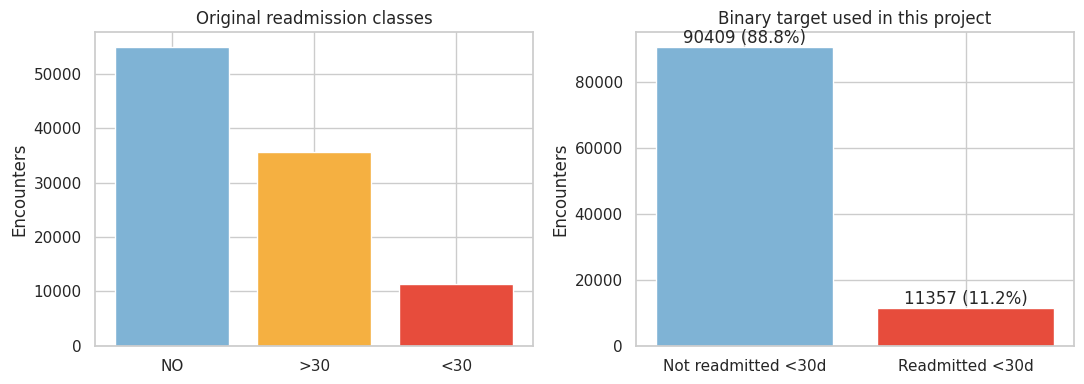

In [11]:
overall_rate = eda[TARGET].mean() * 100
num_cols_eda = ["time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications",
                "number_outpatient", "number_emergency", "number_inpatient", "number_diagnoses"]

def rate_bar(col, ax, title, clip=None, order=None):
    """Bar chart of the 30-day readmission rate for each value of a column."""
    key = eda[col].clip(upper=clip) if clip is not None else eda[col]
    rate = eda.groupby(key)[TARGET].mean() * 100
    if order is not None:
        rate = rate.reindex(order)
    ax.bar(rate.index.astype(str), rate.values, color="#2a7f9e")
    ax.axhline(overall_rate, color="red", linestyle="--", label="overall %.1f%%" % overall_rate)
    ax.set_title(title); ax.set_xlabel(col); ax.set_ylabel("Readmitted <30d (%)")
    ax.tick_params(axis="x", rotation=45); ax.legend()

# 6.1 Readmission class distribution
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
orig = raw_df[TARGET].value_counts()
axes[0].bar(orig.index.astype(str), orig.values, color=["#7fb3d5", "#f5b041", "#e74c3c"][:len(orig)])
axes[0].set_title("Original readmission classes"); axes[0].set_ylabel("Encounters")
binc = df[TARGET].value_counts().sort_index()
axes[1].bar(CLASS_LABELS, binc.values, color=["#7fb3d5", "#e74c3c"])
for i, v in enumerate(binc.values):
    axes[1].text(i, v, "%d (%.1f%%)" % (v, v / len(df) * 100), ha="center", va="bottom")
axes[1].set_title("Binary target used in this project"); axes[1].set_ylabel("Encounters")
plt.tight_layout(); plt.show()

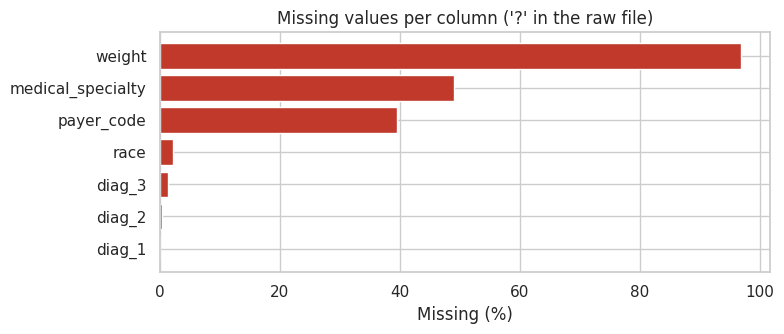

In [12]:
# 6.2 Missing value analysis
plt.figure(figsize=(8, 3.5))
plt.barh(missing_table.index[::-1], missing_table["percent"][::-1], color="#c0392b")
plt.xlabel("Missing (%)"); plt.title("Missing values per column ('?' in the raw file)")
plt.tight_layout(); plt.show()

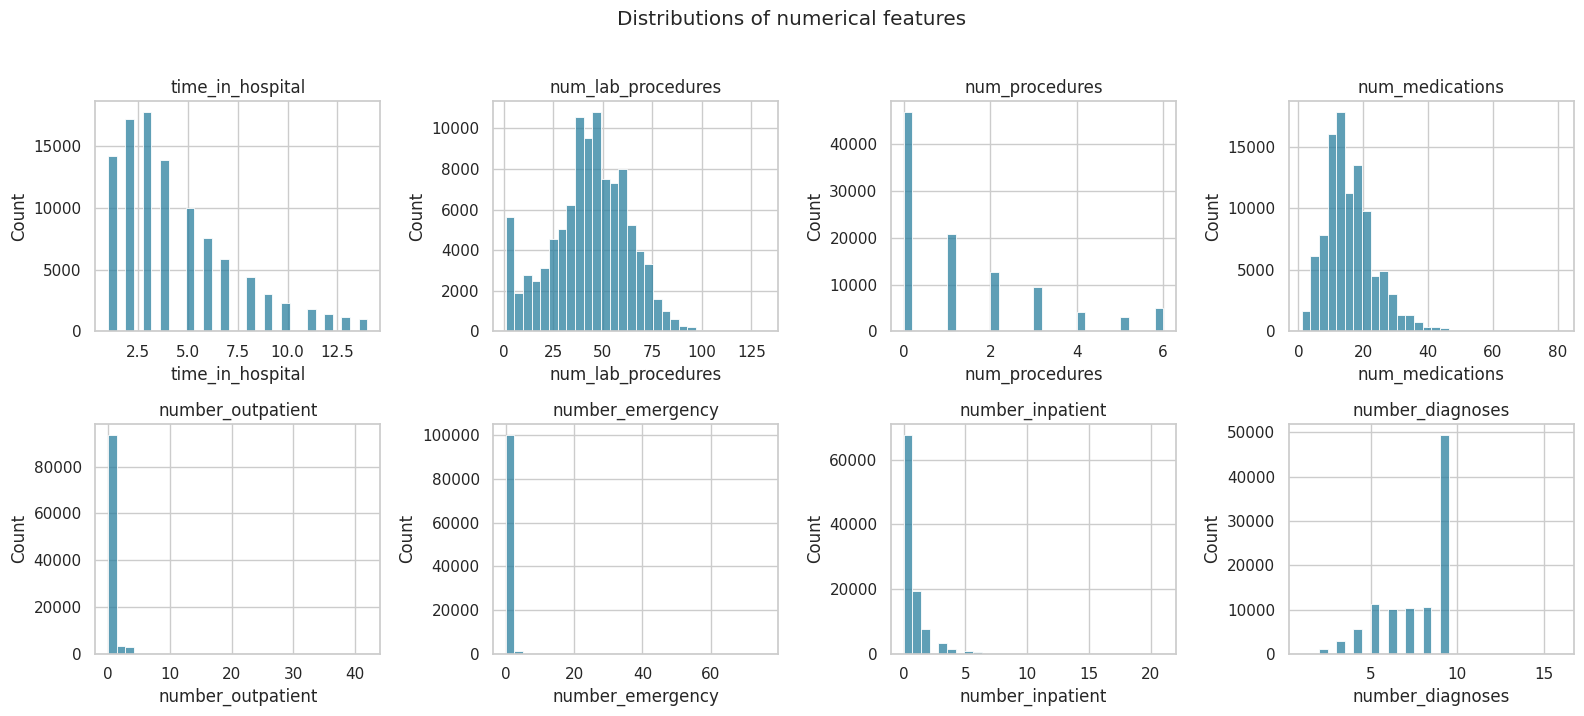

In [13]:
# 6.3 Numerical feature distributions
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.flatten(), num_cols_eda):
    sns.histplot(eda[col], bins=30, ax=ax, color="#2a7f9e")
    ax.set_title(col)
plt.suptitle("Distributions of numerical features", y=1.02)
plt.tight_layout(); plt.show()

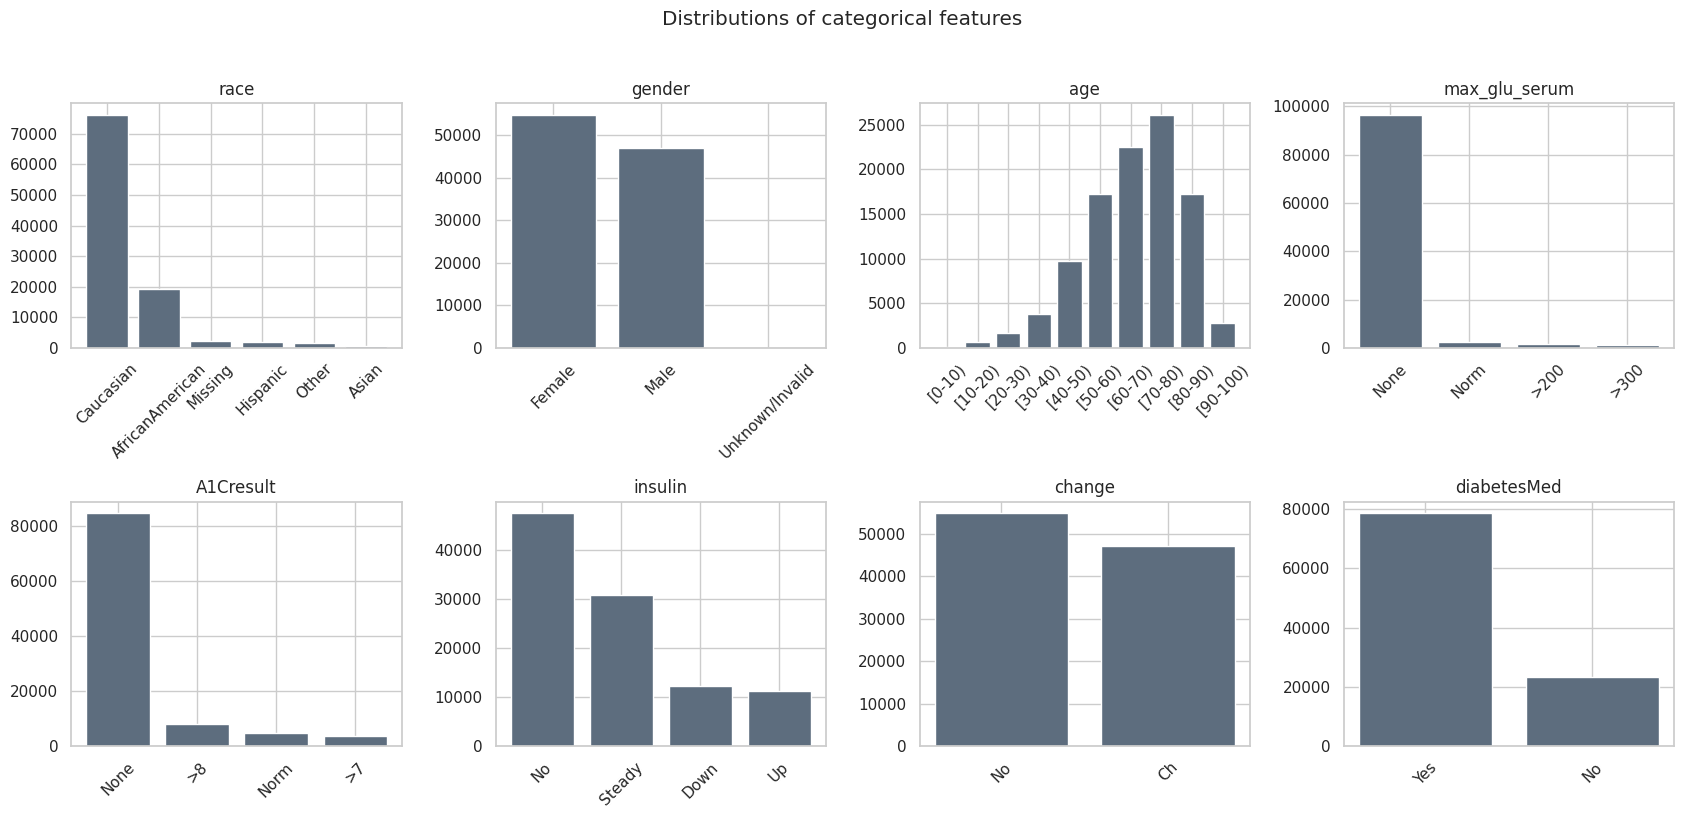

In [14]:
# 6.4 Categorical feature distributions
cat_cols_eda = ["race", "gender", "age", "max_glu_serum", "A1Cresult", "insulin", "change", "diabetesMed"]
fig, axes = plt.subplots(2, 4, figsize=(17, 8))
for ax, col in zip(axes.flatten(), cat_cols_eda):
    counts = eda[col].fillna("Missing").value_counts()
    if col == "age":
        counts = counts.sort_index()
    ax.bar(counts.index.astype(str), counts.values, color="#5d6d7e")
    ax.set_title(col); ax.tick_params(axis="x", rotation=45)
plt.suptitle("Distributions of categorical features", y=1.02)
plt.tight_layout(); plt.show()

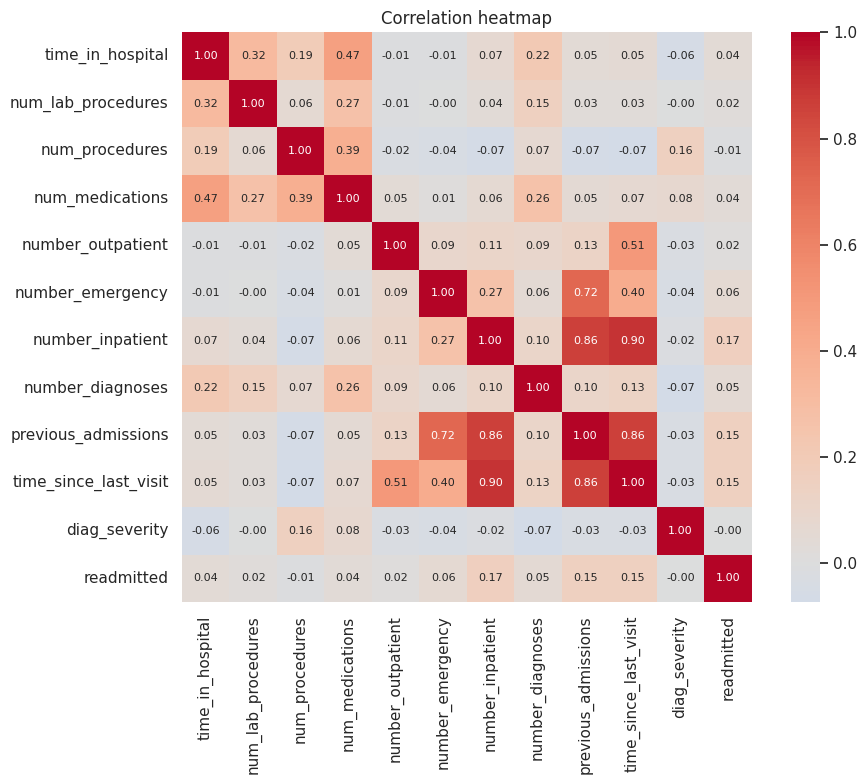

In [15]:
# 6.5 Correlation heatmap (numerical + engineered features + target)
corr_cols = num_cols_eda + ["previous_admissions", "time_since_last_visit", "diag_severity", TARGET]
plt.figure(figsize=(10, 8))
sns.heatmap(eda[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True,
            annot_kws={"size": 8})
plt.title("Correlation heatmap"); plt.tight_layout(); plt.show()

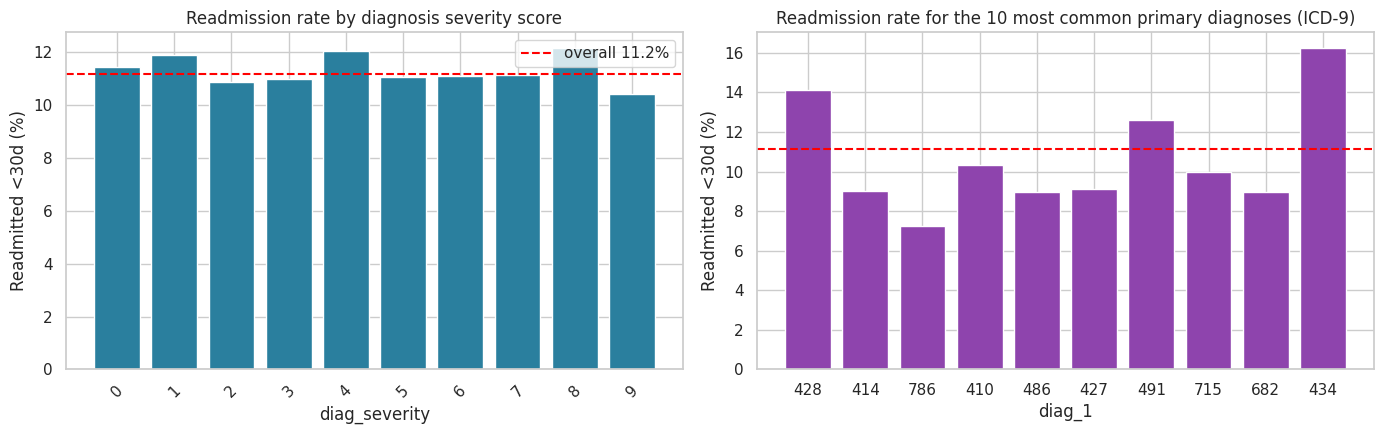

In [16]:
# 6.6 Diagnosis-related analysis
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
rate_bar("diag_severity", axes[0], "Readmission rate by diagnosis severity score")
top_diag = eda["diag_1"].value_counts().head(10).index
d = eda[eda["diag_1"].isin(top_diag)].groupby("diag_1")[TARGET].mean().mul(100).reindex(top_diag)
axes[1].bar(d.index.astype(str), d.values, color="#8e44ad")
axes[1].axhline(overall_rate, color="red", linestyle="--")
axes[1].set_title("Readmission rate for the 10 most common primary diagnoses (ICD-9)")
axes[1].set_xlabel("diag_1"); axes[1].set_ylabel("Readmitted <30d (%)")
plt.tight_layout(); plt.show()

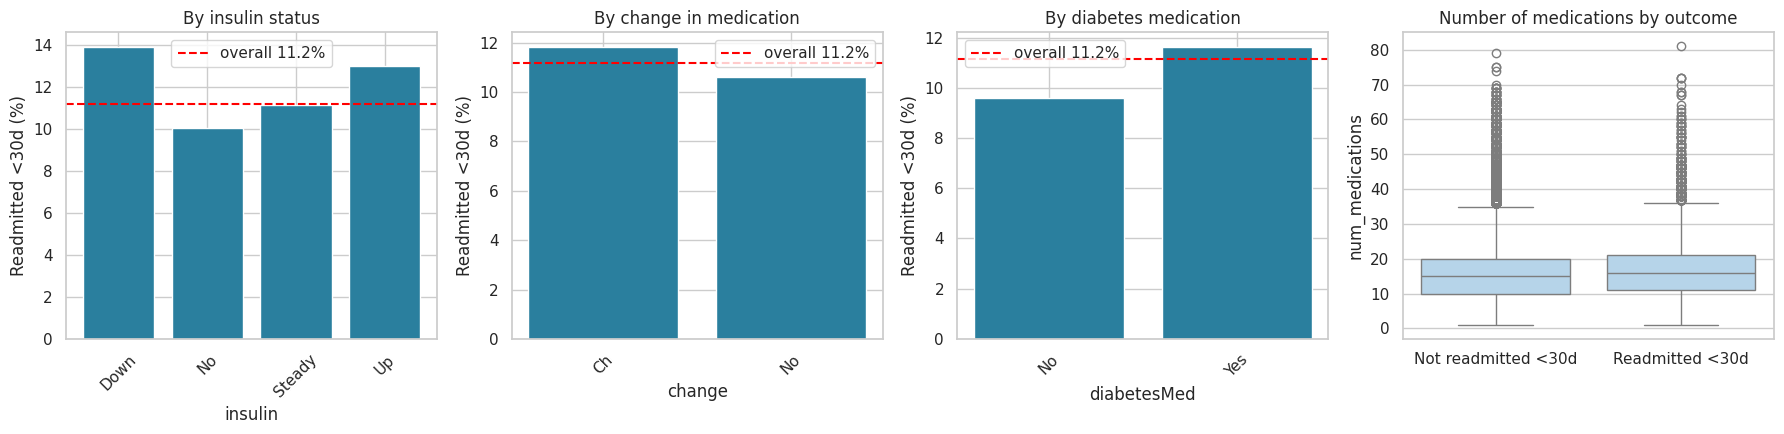

In [17]:
# 6.7 Medication-related analysis
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
rate_bar("insulin", axes[0], "By insulin status")
rate_bar("change", axes[1], "By change in medication")
rate_bar("diabetesMed", axes[2], "By diabetes medication")
sns.boxplot(data=eda, x=TARGET, y="num_medications", ax=axes[3], color="#aed6f1")
axes[3].set_xticks([0, 1]); axes[3].set_xticklabels(CLASS_LABELS)
axes[3].set_title("Number of medications by outcome"); axes[3].set_xlabel("")
plt.tight_layout(); plt.show()

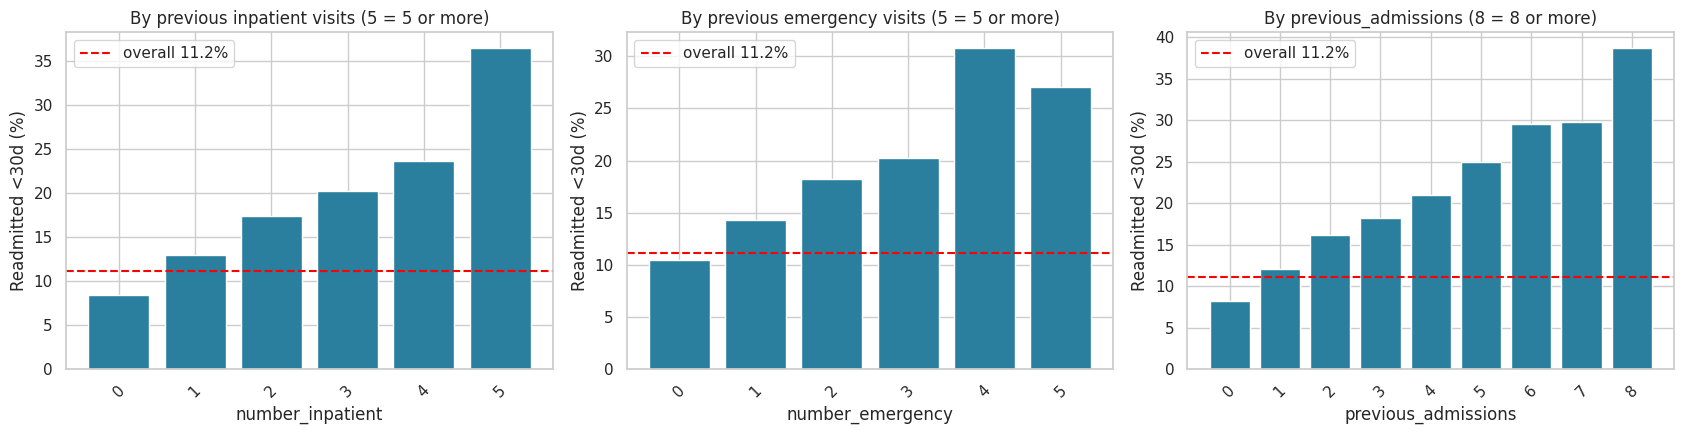

In [18]:
# 6.8 Hospital admission history
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
rate_bar("number_inpatient", axes[0], "By previous inpatient visits (5 = 5 or more)", clip=5)
rate_bar("number_emergency", axes[1], "By previous emergency visits (5 = 5 or more)", clip=5)
rate_bar("previous_admissions", axes[2], "By previous_admissions (8 = 8 or more)", clip=8)
plt.tight_layout(); plt.show()

Mean of each feature for the two outcome groups:


,Not readmitted <30d,Readmitted <30d,difference (%)
time_in_hospital,4.35,4.77,9.6
num_lab_procedures,42.95,44.23,3.0
num_procedures,1.35,1.28,-4.9
num_medications,15.91,16.90,6.2
number_outpatient,0.36,0.44,21.1
number_emergency,0.18,0.36,101.0
number_inpatient,0.56,1.22,117.9
number_diagnoses,7.39,7.69,4.1
previous_admissions,0.74,1.58,113.9
time_since_last_visit,47.19,91.91,94.8


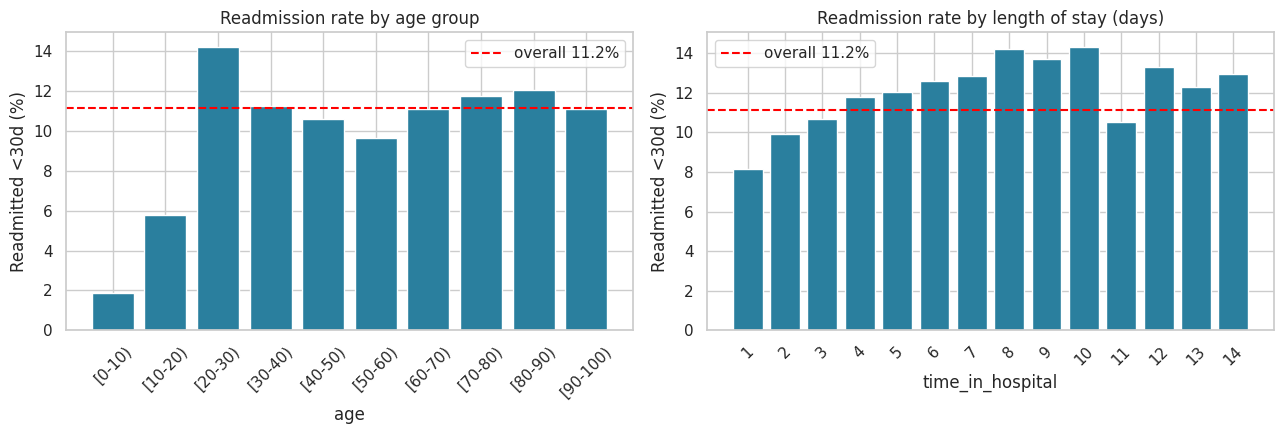

In [19]:
# 6.9 Readmission-related feature comparison
compare_cols = num_cols_eda + ["previous_admissions", "time_since_last_visit", "diag_severity"]
comparison = eda.groupby(TARGET)[compare_cols].mean().T
comparison.columns = CLASS_LABELS
comparison["difference (%)"] = ((comparison[CLASS_LABELS[1]] / comparison[CLASS_LABELS[0]] - 1) * 100).round(1)
print("Mean of each feature for the two outcome groups:")
display(comparison.round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
rate_bar("age", axes[0], "Readmission rate by age group")
rate_bar("time_in_hospital", axes[1], "Readmission rate by length of stay (days)")
plt.tight_layout(); plt.show()

## 7. Train-test split, encoding, scaling and SMOTE

Order of operations (this order is what prevents data leakage):

1. **Split 80:20** with `random_state=42` and `stratify=y`, on the raw cleaned data.
2. **Fit the preprocessor on the training split only**: mode/median imputation values and one
   `LabelEncoder` per categorical column. The encoders are stored for deployment; a category that
   was never seen in training is replaced by the most frequent training category.
3. **StandardScaler** fitted on the training split, then applied to the test split.
   Scaling is needed by Logistic Regression and by SMOTE (which uses distances); tree models are not harmed by it.
4. **SMOTE on the training split only.** Only about 11% of encounters are class 1, so a model can reach
   89% accuracy by never predicting a readmission. SMOTE creates synthetic minority examples so the
   model sees a balanced training set. The test set is **never** resampled: it keeps the real 11%
   rate, so the reported scores reflect real-world performance.

In [20]:
X_raw = df.drop(columns=[TARGET])
y_all = df[TARGET].values

X_train_df, X_test_df, y_train, y_test = train_test_split(
    X_raw, y_all, test_size=0.20, random_state=RANDOM_STATE, stratify=y_all)

prep = fit_preprocessor(X_train_df)                  # learned from TRAINING data only
feature_columns = prep["feature_columns"]
label_encoders_dict = prep["label_encoders"]

X_train_enc = transform_features(X_train_df, prep).values
X_test_enc, unseen_test = transform_features(X_test_df, prep, return_unseen=True)
X_test_enc = X_test_enc.values

scaler = StandardScaler().fit(X_train_enc)           # fitted on TRAINING data only
X_train_scaled = scaler.transform(X_train_enc)
X_test_scaled = scaler.transform(X_test_enc)

smote = SMOTE(random_state=RANDOM_STATE)             # TRAINING data only
X_train_bal, y_train_bal = smote.fit_resample(X_train_scaled, y_train)

print("Features used by the models (%d):" % len(feature_columns)); print(feature_columns)
print("\nCategorical columns label-encoded:", len(label_encoders_dict))
print("Imputation values learned from training data (columns that had gaps):",
      {c: prep["impute_values"][c] for c in ["race", "diag_1", "diag_2", "diag_3"]})
print("Test-set categories never seen in training (mapped to the training mode):",
      {k: len(v) for k, v in unseen_test.items()} or "none")
print("\nTrain before SMOTE:", X_train_scaled.shape, "class counts", np.bincount(y_train))
print("Train after  SMOTE:", X_train_bal.shape, "class counts", np.bincount(y_train_bal))
print("Test (untouched)  :", X_test_scaled.shape, "class counts", np.bincount(y_test),
      "-> %.2f%% positive" % (y_test.mean() * 100))

Features used by the models (51):
['race', 'gender', 'age', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1', 'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed', 'previous_admissions', 'medication_load', 'time_since_last_visit', 'diag_1_num', 'diag_2_num', 'diag_3_num', 'diag_severity']

Categorical columns label-encoded: 33
Imputation values learned from training data (columns that had gaps): {'r

## 8. Machine learning model training
Four algorithms are trained on the scaled, SMOTE-balanced training data and tested on the
untouched test set, at the default 0.5 threshold.

In [21]:
models = {
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "XGBoost": XGBClassifier(n_estimators=200, learning_rate=0.1, max_depth=6,
                             random_state=RANDOM_STATE, eval_metric="logloss", n_jobs=-1),
}

preds, probas, fitted = {}, {}, {}
for name, model in models.items():
    t0 = time.time()
    fitted[name] = clone(model).fit(X_train_bal, y_train_bal)
    preds[name] = fitted[name].predict(X_test_scaled)
    probas[name] = fitted[name].predict_proba(X_test_scaled)[:, 1]
    print("=" * 62)
    print("%s  (trained in %.0fs)" % (name, time.time() - t0))
    print(classification_report(y_test, preds[name], target_names=CLASS_LABELS, zero_division=0))

Random Forest  (trained in 91s)
                     precision    recall  f1-score   support

Not readmitted <30d       0.89      0.99      0.94     18083
    Readmitted <30d       0.45      0.03      0.06      2271

           accuracy                           0.89     20354
          macro avg       0.67      0.51      0.50     20354
       weighted avg       0.84      0.89      0.84     20354

Decision Tree  (trained in 5s)
                     precision    recall  f1-score   support

Not readmitted <30d       0.89      0.86      0.88     18083
    Readmitted <30d       0.15      0.19      0.17      2271

           accuracy                           0.79     20354
          macro avg       0.52      0.53      0.52     20354
       weighted avg       0.81      0.79      0.80     20354

Logistic Regression  (trained in 1s)
                     precision    recall  f1-score   support

Not readmitted <30d       0.92      0.66      0.77     18083
    Readmitted <30d       0.17      0.5

## 9. Model evaluation and comparison
Accuracy alone is misleading here: predicting "not readmitted" for everyone already gives about 89%
accuracy with zero clinical value. **Recall for class 1** (how many real readmissions are caught),
precision, F1 and the threshold-independent **ROC-AUC** and **PR-AUC** are the meaningful measures.

In [22]:
rows = []
for name in models:
    rep = classification_report(y_test, preds[name], output_dict=True, zero_division=0)
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, preds[name]),
        "Precision (class 1)": rep["1"]["precision"],
        "Recall (class 1)": rep["1"]["recall"],
        "F1 (class 1)": rep["1"]["f1-score"],
        "ROC-AUC": roc_auc_score(y_test, probas[name]),
        "PR-AUC": average_precision_score(y_test, probas[name]),
        "Precision (class 0)": rep["0"]["precision"],
        "Recall (class 0)": rep["0"]["recall"],
        "F1 (class 0)": rep["0"]["f1-score"],
    })
metrics_df = pd.DataFrame(rows).sort_values("ROC-AUC", ascending=False).reset_index(drop=True)
print("Model comparison on the test set (default threshold 0.5):")
display(metrics_df[["Model", "Accuracy", "Precision (class 1)", "Recall (class 1)",
                    "F1 (class 1)", "ROC-AUC", "PR-AUC"]].round(4))
print("Class-wise precision, recall and F1:")
display(metrics_df[["Model", "Precision (class 0)", "Recall (class 0)", "F1 (class 0)",
                    "Precision (class 1)", "Recall (class 1)", "F1 (class 1)"]].round(4))
print("Baseline: always predicting class 0 gives accuracy %.4f and recall 0." % (1 - y_test.mean()))

Model comparison on the test set (default threshold 0.5):


,Model,Accuracy,Precision (class 1),Recall (class 1),F1 (class 1),ROC-AUC,PR-AUC
0,XGBoost,0.8885,0.5062,0.0181,0.0349,0.6810,0.2254
1,Random Forest,0.8876,0.4518,0.0330,0.0616,0.6450,0.2014
2,Logistic Regression,0.6473,0.1650,0.5324,0.2520,0.6398,0.1968
3,Decision Tree,0.7894,0.1491,0.1885,0.1665,0.5267,0.1186


Class-wise precision, recall and F1:


,Model,Precision (class 0),Recall (class 0),F1 (class 0),Precision (class 1),Recall (class 1),F1 (class 1)
0,XGBoost,0.8900,0.9978,0.9408,0.5062,0.0181,0.0349
1,Random Forest,0.8912,0.9950,0.9402,0.4518,0.0330,0.0616
2,Logistic Regression,0.9185,0.6617,0.7692,0.1650,0.5324,0.2520
3,Decision Tree,0.8946,0.8649,0.8795,0.1491,0.1885,0.1665


Baseline: always predicting class 0 gives accuracy 0.8884 and recall 0.


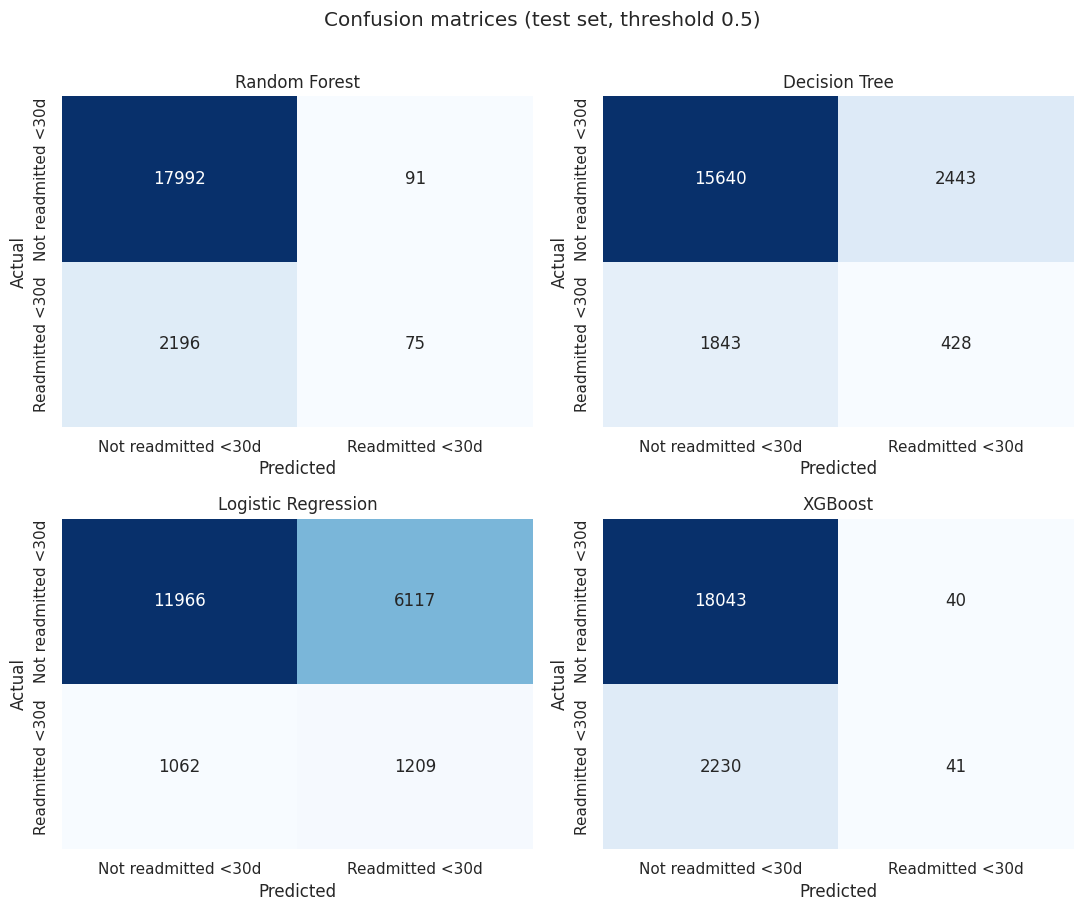

In [23]:
# Confusion matrix for each model
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, name in zip(axes.flatten(), models):
    sns.heatmap(confusion_matrix(y_test, preds[name]), annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=CLASS_LABELS, yticklabels=CLASS_LABELS, cbar=False)
    ax.set_title(name); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.suptitle("Confusion matrices (test set, threshold 0.5)", y=1.01)
plt.tight_layout(); plt.show()

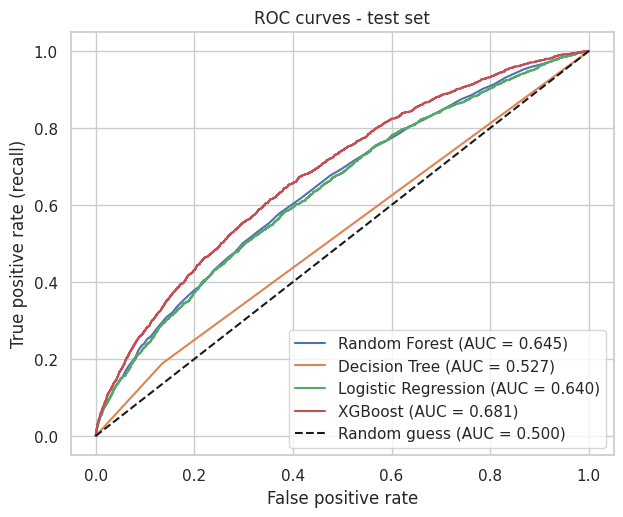

In [24]:
# ROC curves for all models
plt.figure(figsize=(7, 5.5))
for name in models:
    fpr, tpr, _ = roc_curve(y_test, probas[name])
    plt.plot(fpr, tpr, label="%s (AUC = %.3f)" % (name, roc_auc_score(y_test, probas[name])))
plt.plot([0, 1], [0, 1], "k--", label="Random guess (AUC = 0.500)")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate (recall)")
plt.title("ROC curves - test set"); plt.legend(); plt.show()

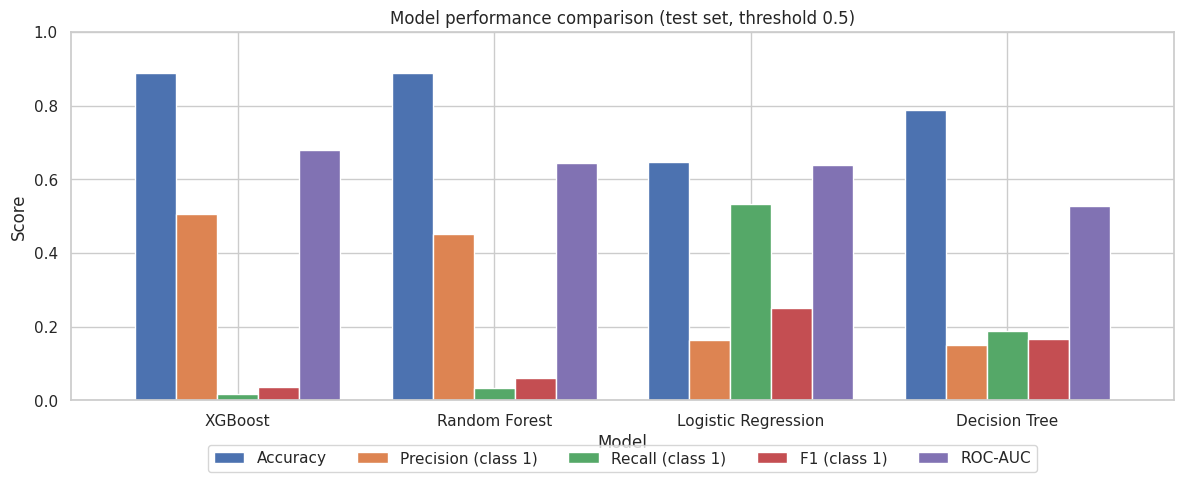

In [25]:
# Visual comparison of the main metrics
plot_cols = ["Accuracy", "Precision (class 1)", "Recall (class 1)", "F1 (class 1)", "ROC-AUC"]
ax = metrics_df.set_index("Model")[plot_cols].plot(kind="bar", figsize=(12, 5), width=0.8)
ax.set_title("Model performance comparison (test set, threshold 0.5)")
ax.set_ylabel("Score"); ax.set_ylim(0, 1); ax.tick_params(axis="x", rotation=0)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=5)
plt.tight_layout(); plt.show()

## 10. Cross-validation (5-fold, leak-free)
An `imblearn` Pipeline of **StandardScaler -> SMOTE -> model** is evaluated with stratified 5-fold
cross-validation on the training data. Inside every fold the scaler and SMOTE are fitted on that
fold's training part only, and the validation part keeps the real class balance.

The project requirement is the Random Forest pipeline; the same procedure is repeated for the other
three models so that the best model can be chosen without touching the test set (Section 11).

In [26]:
def make_pipeline(model):
    return ImbPipeline(steps=[("scaler", StandardScaler()),
                              ("smote", SMOTE(random_state=RANDOM_STATE)),
                              ("model", model)])

skf5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"roc_auc": "roc_auc", "pr_auc": "average_precision",
           "recall_1": "recall", "precision_1": "precision", "f1_1": "f1"}

cv_rows, cv_fold_auc = [], {}
for name, model in models.items():
    t0 = time.time()
    res = cross_validate(make_pipeline(clone(model)), X_train_enc, y_train,
                         cv=skf5, scoring=scoring, n_jobs=1)
    cv_fold_auc[name] = res["test_roc_auc"]
    cv_rows.append({"Model": name,
                    "CV ROC-AUC": res["test_roc_auc"].mean(), "CV ROC-AUC std": res["test_roc_auc"].std(),
                    "CV PR-AUC": res["test_pr_auc"].mean(),
                    "CV Recall (class 1)": res["test_recall_1"].mean(),
                    "CV Precision (class 1)": res["test_precision_1"].mean(),
                    "CV F1 (class 1)": res["test_f1_1"].mean()})
    print("%-20s fold ROC-AUC: %s | mean = %.4f  (%.0fs)"
          % (name, np.round(res["test_roc_auc"], 4), res["test_roc_auc"].mean(), time.time() - t0))

print("\nRandom Forest pipeline (StandardScaler + SMOTE + Random Forest)")
print("Individual fold ROC-AUC:", np.round(cv_fold_auc["Random Forest"], 4))
print("Mean ROC-AUC: %.4f" % cv_fold_auc["Random Forest"].mean())

Random Forest        fold ROC-AUC: [0.6372 0.6383 0.6415 0.632  0.6418] | mean = 0.6382  (343s)
Decision Tree        fold ROC-AUC: [0.5171 0.5316 0.5262 0.5238 0.5297] | mean = 0.5257  (19s)
Logistic Regression  fold ROC-AUC: [0.6188 0.6305 0.6349 0.6252 0.6324] | mean = 0.6284  (7s)
XGBoost              fold ROC-AUC: [0.6622 0.6674 0.6701 0.6638 0.6712] | mean = 0.6670  (34s)

Random Forest pipeline (StandardScaler + SMOTE + Random Forest)
Individual fold ROC-AUC: [0.6372 0.6383 0.6415 0.632  0.6418]
Mean ROC-AUC: 0.6382


## 11. Best model selection
The model is chosen from the cross-validation results, not assumed. Because the decision threshold
is optimized later (Section 14), the choice is based on the two threshold-independent measures:
**ROC-AUC** (overall ranking ability) and **PR-AUC** (ranking ability on the rare readmitted class).
Each model is ranked on both; the lowest average rank wins, with ROC-AUC as the tie-breaker.
Recall, precision and F1 at threshold 0.5 are shown for information.

In [27]:
cv_table = pd.DataFrame(cv_rows)
cv_table["Rank ROC-AUC"] = cv_table["CV ROC-AUC"].rank(ascending=False)
cv_table["Rank PR-AUC"] = cv_table["CV PR-AUC"].rank(ascending=False)
cv_table["Selection score (avg rank)"] = (cv_table["Rank ROC-AUC"] + cv_table["Rank PR-AUC"]) / 2
cv_table = cv_table.sort_values(["Selection score (avg rank)", "CV ROC-AUC"],
                                ascending=[True, False]).reset_index(drop=True)
display(cv_table.round(4))

best_name = cv_table.iloc[0]["Model"]
print("Selected model:", best_name)
print("Its test-set ROC-AUC before tuning: %.4f" % roc_auc_score(y_test, probas[best_name]))

,Model,CV ROC-AUC,CV ROC-AUC std,CV PR-AUC,CV Recall (class 1),CV Precision (class 1),CV F1 (class 1),Rank ROC-AUC,Rank PR-AUC,Selection score (avg rank)
0,XGBoost,0.6670,0.0035,0.2173,0.0195,0.4724,0.0374,1.0,1.0,1.0
1,Random Forest,0.6382,0.0036,0.1925,0.0281,0.3751,0.0522,2.0,2.0,2.0
2,Logistic Regression,0.6284,0.0058,0.1893,0.5188,0.1593,0.2438,3.0,3.0,3.0
3,Decision Tree,0.5257,0.0051,0.1184,0.1825,0.1487,0.1638,4.0,4.0,4.0


Selected model: XGBoost
Its test-set ROC-AUC before tuning: 0.6810


## 12. Hyperparameter tuning
`RandomizedSearchCV` (`n_iter=15`, `cv=3`, scoring = ROC-AUC) searches the selected model's
parameters. The search runs on the **whole pipeline** (scaler -> SMOTE -> model) using the real
training data, so every candidate is scored on validation folds that contain no synthetic samples.

Random Forest depth is capped at 15: very deep forests gave no better validation score, make SHAP
extremely slow and produce model files too large for GitHub / Streamlit Cloud.

This is the slowest cell of the notebook.

In [28]:
param_spaces = {
    "Random Forest": {
        "model__n_estimators": [100, 200, 300],
        "model__max_depth": [6, 8, 10, 12, 15],
        "model__min_samples_split": [2, 5, 10],
        "model__min_samples_leaf": [1, 2, 4, 8],
        "model__max_features": ["sqrt", "log2"],
    },
    "Decision Tree": {
        "model__max_depth": [3, 5, 8, 10, 15, 20],
        "model__min_samples_split": [2, 5, 10, 20],
        "model__min_samples_leaf": [1, 2, 4, 8, 16],
        "model__criterion": ["gini", "entropy"],
    },
    "Logistic Regression": [
        {"model__C": [0.001, 0.01, 0.1, 1, 10, 100], "model__penalty": ["l2"], "model__solver": ["lbfgs"]},
        {"model__C": [0.001, 0.01, 0.1, 1, 10, 100], "model__penalty": ["l1", "l2"], "model__solver": ["liblinear"]},
    ],
    "XGBoost": {
        "model__n_estimators": [100, 200, 300, 400],
        "model__max_depth": [3, 4, 5, 6, 8],
        "model__learning_rate": [0.01, 0.05, 0.1, 0.2],
        "model__subsample": [0.7, 0.8, 1.0],
        "model__colsample_bytree": [0.7, 0.8, 1.0],
    },
}

skf3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
search = RandomizedSearchCV(
    estimator=make_pipeline(clone(models[best_name])),
    param_distributions=param_spaces[best_name],
    n_iter=15, scoring="roc_auc", cv=skf3, random_state=RANDOM_STATE,
    n_jobs=1, refit=True, verbose=1)

t0 = time.time()
search.fit(X_train_enc, y_train)
print("Tuning finished in %.1f min" % ((time.time() - t0) / 60))

tuned_pipeline = search.best_estimator_
best_params = {k.replace("model__", ""): v for k, v in search.best_params_.items()}
print("\nBest parameters for %s:" % best_name, best_params)
print("Best cross-validated ROC-AUC: %.4f" % search.best_score_)

cv_results = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
print("\nTop 5 parameter combinations:")
display(cv_results[["rank_test_score", "mean_test_score", "std_test_score", "params"]].head(5))

tuned_test_auc = roc_auc_score(y_test, tuned_pipeline.predict_proba(X_test_enc)[:, 1])
print("Test ROC-AUC  untuned: %.4f  ->  tuned: %.4f" % (roc_auc_score(y_test, probas[best_name]), tuned_test_auc))

Fitting 3 folds for each of 15 candidates, totalling 45 fits
Tuning finished in 5.6 min

Best parameters for XGBoost: {'subsample': 0.7, 'n_estimators': 300, 'max_depth': 5, 'learning_rate': 0.1, 'colsample_bytree': 0.8}
Best cross-validated ROC-AUC: 0.6640

Top 5 parameter combinations:


,rank_test_score,mean_test_score,std_test_score,params
9,1,0.663962,0.001141,"{'model__subsample': 0.7, 'model__n_estimators..."
14,2,0.663506,0.000901,"{'model__subsample': 0.8, 'model__n_estimators..."
13,3,0.662262,0.002542,"{'model__subsample': 1.0, 'model__n_estimators..."
0,4,0.662042,0.003603,"{'model__subsample': 0.8, 'model__n_estimators..."
2,5,0.658405,0.003397,"{'model__subsample': 0.7, 'model__n_estimators..."


Test ROC-AUC  untuned: 0.6810  ->  tuned: 0.6785


## 13. Probability calibration
The tuned model was trained on a SMOTE-balanced set (50% positives), so its raw probabilities are
too high for the real world, where about 11% of patients are readmitted. A clinician reading
"40% risk" needs that number to mean roughly 40 out of 100 similar patients.

`CalibratedClassifierCV` with **sigmoid** (Platt) calibration fixes this. With `cv=3` and
`ensemble=False`, it collects out-of-fold predictions on real (un-resampled) training folds, fits
the sigmoid on them, and then refits the pipeline on all training data.

- `calibrated_model` -> used for every prediction shown to the user.
- `best_model_raw` -> the tuned, uncalibrated model inside it, kept for SHAP.
  Calibration only rescales this model's output, so the SHAP explanation matches the deployed model.

,ROC-AUC,Brier score (lower is better),Mean predicted probability
"Tuned, uncalibrated",0.6785,0.0942,0.1180
Tuned + calibrated,0.6785,0.0946,0.1112


Actual readmission rate in the test set: 0.1116


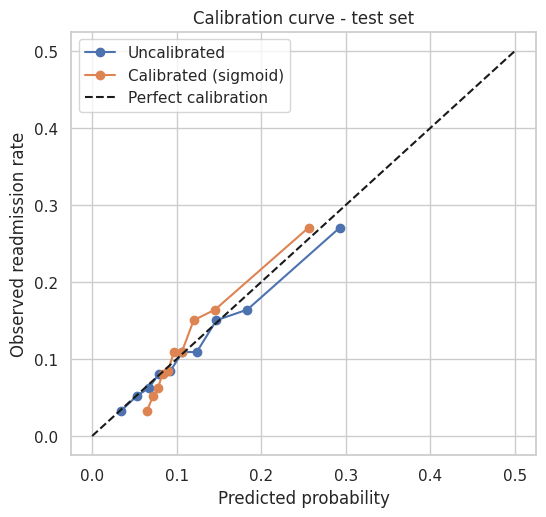

In [29]:
calibrated_model = CalibratedClassifierCV(estimator=clone(tuned_pipeline), method="sigmoid",
                                          cv=skf3, ensemble=False)
calibrated_model.fit(X_train_enc, y_train)

final_pipeline = calibrated_model.calibrated_classifiers_[0].estimator   # refit on all training data
best_model_raw = final_pipeline.named_steps["model"]                     # tuned + uncalibrated (for SHAP)
scaler = final_pipeline.named_steps["scaler"]                            # the scaler the final model uses
assert np.allclose(scaler.mean_, X_train_enc.mean(axis=0))               # same as Section 7 scaler

proba_uncal = final_pipeline.predict_proba(X_test_enc)[:, 1]
proba_cal = calibrated_model.predict_proba(X_test_enc)[:, 1]

calib_table = pd.DataFrame({
    "ROC-AUC": [roc_auc_score(y_test, proba_uncal), roc_auc_score(y_test, proba_cal)],
    "Brier score (lower is better)": [brier_score_loss(y_test, proba_uncal), brier_score_loss(y_test, proba_cal)],
    "Mean predicted probability": [proba_uncal.mean(), proba_cal.mean()],
}, index=["Tuned, uncalibrated", "Tuned + calibrated"])
display(calib_table.round(4))
print("Actual readmission rate in the test set: %.4f" % y_test.mean())

plt.figure(figsize=(6, 5.5))
for label, p in [("Uncalibrated", proba_uncal), ("Calibrated (sigmoid)", proba_cal)]:
    frac_pos, mean_pred = calibration_curve(y_test, p, n_bins=10, strategy="quantile")
    plt.plot(mean_pred, frac_pos, marker="o", label=label)
lim = max(0.5, float(np.quantile(proba_uncal, 0.99)))
plt.plot([0, lim], [0, lim], "k--", label="Perfect calibration")
plt.xlabel("Predicted probability"); plt.ylabel("Observed readmission rate")
plt.title("Calibration curve - test set"); plt.legend(); plt.show()

## 14. Threshold optimization
With only about 11% positives, calibrated probabilities are mostly well below 0.5, so the default
0.5 cut-off would label almost nobody as "readmitted".

The threshold is chosen from **out-of-fold predictions on the training data**: the training set is
split into 3 folds, and each fold is predicted by a calibrated model trained on the other two.
The test set plays no part in choosing the threshold, so the test report below stays unbiased.

- `THRESHOLD_STRATEGY = "f1"` (default): the threshold with the best F1 for class 1.
- `THRESHOLD_STRATEGY = "recall"`: the highest threshold that still catches at least
  `TARGET_RECALL` of readmissions - use this if missing a readmission is judged much worse than a false alarm.

Out-of-fold predictions ready (1.1 min). OOF ROC-AUC: 0.6640
F1-optimal threshold      : 0.1198 (precision 0.199, recall 0.441, F1 0.274)
Recall >= 0.70 threshold  : 0.0935 (precision 0.155, recall 0.700, F1 0.254)

Chosen threshold (f1 strategy): 0.1198


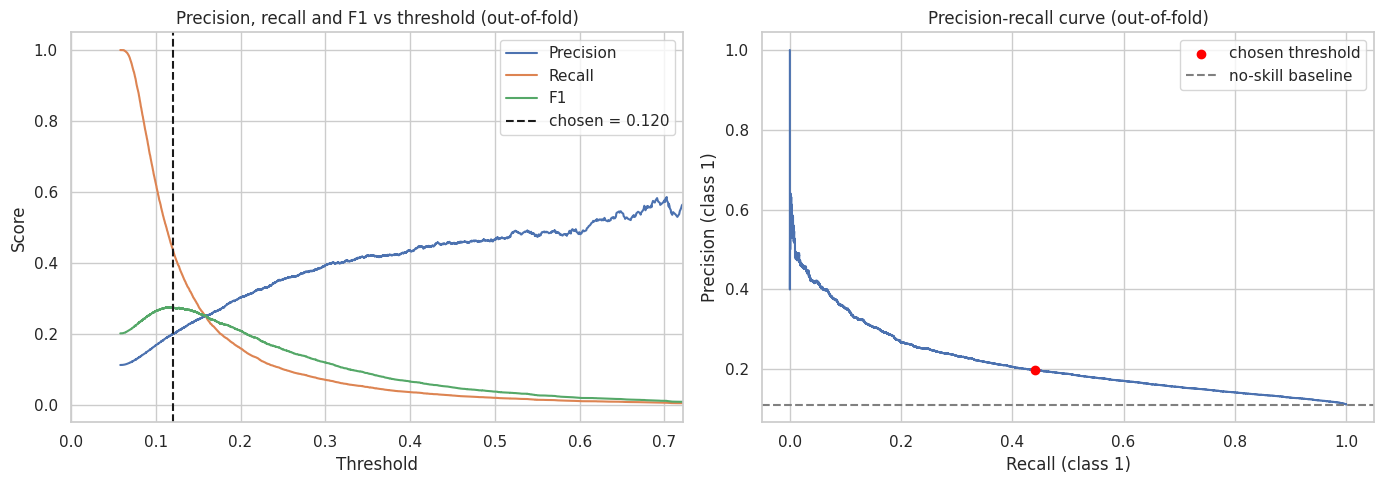

In [30]:
THRESHOLD_STRATEGY = "f1"      # "f1" or "recall"
TARGET_RECALL = 0.70           # only used when THRESHOLD_STRATEGY == "recall"

t0 = time.time()
oof_proba = cross_val_predict(clone(calibrated_model), X_train_enc, y_train,
                              cv=skf3, method="predict_proba")[:, 1]
print("Out-of-fold predictions ready (%.1f min). OOF ROC-AUC: %.4f"
      % ((time.time() - t0) / 60, roc_auc_score(y_train, oof_proba)))

prec, rec, thr = precision_recall_curve(y_train, oof_proba)
prec, rec = prec[:-1], rec[:-1]                     # align with thresholds
f1 = 2 * prec * rec / (prec + rec + 1e-12)

f1_idx = int(np.argmax(f1))
recall_ok = np.where(rec >= TARGET_RECALL)[0]
recall_idx = int(recall_ok[-1]) if len(recall_ok) else 0
best_idx = f1_idx if THRESHOLD_STRATEGY == "f1" else recall_idx
chosen_threshold = float(thr[best_idx])

print("F1-optimal threshold      : %.4f (precision %.3f, recall %.3f, F1 %.3f)"
      % (thr[f1_idx], prec[f1_idx], rec[f1_idx], f1[f1_idx]))
print("Recall >= %.2f threshold  : %.4f (precision %.3f, recall %.3f, F1 %.3f)"
      % (TARGET_RECALL, thr[recall_idx], prec[recall_idx], rec[recall_idx], f1[recall_idx]))
print("\nChosen threshold (%s strategy): %.4f" % (THRESHOLD_STRATEGY, chosen_threshold))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(thr, prec, label="Precision"); axes[0].plot(thr, rec, label="Recall"); axes[0].plot(thr, f1, label="F1")
axes[0].axvline(chosen_threshold, color="k", linestyle="--", label="chosen = %.3f" % chosen_threshold)
axes[0].set_xlim(0, min(1.0, float(np.quantile(oof_proba, 0.999)) + 0.02))
axes[0].set_xlabel("Threshold"); axes[0].set_ylabel("Score")
axes[0].set_title("Precision, recall and F1 vs threshold (out-of-fold)"); axes[0].legend()
axes[1].plot(rec, prec); axes[1].scatter(rec[best_idx], prec[best_idx], color="red", zorder=5, label="chosen threshold")
axes[1].axhline(y_train.mean(), color="grey", linestyle="--", label="no-skill baseline")
axes[1].set_xlabel("Recall (class 1)"); axes[1].set_ylabel("Precision (class 1)")
axes[1].set_title("Precision-recall curve (out-of-fold)"); axes[1].legend()
plt.tight_layout(); plt.show()

Classification report on the TEST set at threshold 0.1198
                     precision    recall  f1-score   support

Not readmitted <30d       0.92      0.78      0.84     18083
    Readmitted <30d       0.20      0.46      0.28      2271

           accuracy                           0.74     20354
          macro avg       0.56      0.62      0.56     20354
       weighted avg       0.84      0.74      0.78     20354



,Default threshold 0.50,Chosen threshold 0.120
Recall (class 1),0.0211,0.4566
Precision (class 1),0.5106,0.2048
F1 (class 1),0.0406,0.2828
Accuracy,0.8885,0.7416


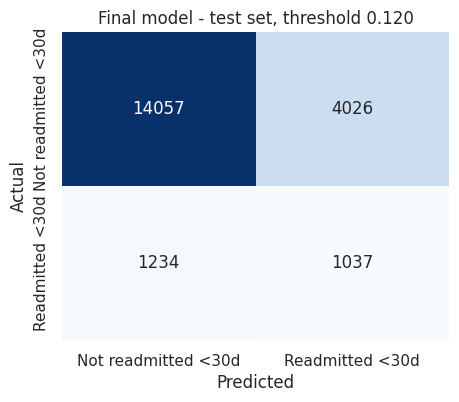

In [31]:
# Final, unbiased evaluation of the deployed model on the untouched test set
y_pred_final = (proba_cal >= chosen_threshold).astype(int)
print("Classification report on the TEST set at threshold %.4f" % chosen_threshold)
print(classification_report(y_test, y_pred_final, target_names=CLASS_LABELS, zero_division=0))

final_metrics = {
    "ROC-AUC": float(roc_auc_score(y_test, proba_cal)),
    "PR-AUC": float(average_precision_score(y_test, proba_cal)),
    "Recall (class 1)": float(recall_score(y_test, y_pred_final)),
    "Precision (class 1)": float(precision_score(y_test, y_pred_final, zero_division=0)),
    "F1 (class 1)": float(f1_score(y_test, y_pred_final)),
    "Accuracy": float(accuracy_score(y_test, y_pred_final)),
}
at_half = (proba_cal >= 0.5).astype(int)
display(pd.DataFrame({
    "Default threshold 0.50": [recall_score(y_test, at_half), precision_score(y_test, at_half, zero_division=0),
                               f1_score(y_test, at_half), accuracy_score(y_test, at_half)],
    "Chosen threshold %.3f" % chosen_threshold: [final_metrics["Recall (class 1)"], final_metrics["Precision (class 1)"],
                                                 final_metrics["F1 (class 1)"], final_metrics["Accuracy"]],
}, index=["Recall (class 1)", "Precision (class 1)", "F1 (class 1)", "Accuracy"]).round(4))

plt.figure(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test, y_pred_final), annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=CLASS_LABELS, yticklabels=CLASS_LABELS)
plt.title("Final model - test set, threshold %.3f" % chosen_threshold)
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.show()

## 15. Save trained model and artifacts
Everything needed for inference is stored in the `artifacts/` folder and zipped.

| File | Content |
|---|---|
| `model.joblib` | calibrated model (scaler + tuned model + sigmoid calibration) - makes the predictions |
| `model_raw.joblib` | tuned uncalibrated model - used by SHAP |
| `scaler.joblib` | fitted StandardScaler |
| `preprocessor.joblib` | imputation values, label encoders, column lists |
| `label_encoders_dict.joblib` | the label encoders on their own |
| `feature_columns.json` | feature names in training order |
| `config.json` | selected model name, decision threshold, parameters, metrics, library versions, form options |
| `lime_background.joblib` | 2,000 encoded training rows that LIME needs to build its explainer |

**To download:** the cell below offers `artifacts.zip` automatically in Colab. You can also open the
folder icon on the left, right-click `artifacts.zip` and choose *Download*.

In [32]:
os.makedirs("artifacts", exist_ok=True)

joblib.dump(calibrated_model, "artifacts/model.joblib", compress=3)
joblib.dump(best_model_raw, "artifacts/model_raw.joblib", compress=3)
joblib.dump(scaler, "artifacts/scaler.joblib")
joblib.dump(prep, "artifacts/preprocessor.joblib")
joblib.dump(label_encoders_dict, "artifacts/label_encoders_dict.joblib")

rng = np.random.RandomState(RANDOM_STATE)
bg_idx = rng.choice(len(X_train_enc), size=min(2000, len(X_train_enc)), replace=False)
joblib.dump(X_train_enc[bg_idx], "artifacts/lime_background.joblib", compress=3)

with open("artifacts/feature_columns.json", "w") as f:
    json.dump(feature_columns, f, indent=2)

count_cols = ["time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications",
              "number_outpatient", "number_emergency", "number_inpatient", "number_diagnoses"]
ui_options = {
    "categorical": {c: [str(v) for v in label_encoders_dict[c].classes_]
                    for c in ["race", "gender", "age", "max_glu_serum", "A1Cresult",
                              "insulin", "change", "diabetesMed"]},
    "ids": {c: sorted(int(v) for v in X_train_df[c].unique())
            for c in ["admission_type_id", "discharge_disposition_id", "admission_source_id"]},
    "numeric": {c: {"min": int(X_train_df[c].min()), "max": int(X_train_df[c].max()),
                    "median": float(X_train_df[c].median())} for c in count_cols},
}
config = {
    "best_model_name": best_name,
    "decision_threshold": chosen_threshold,
    "threshold_strategy": THRESHOLD_STRATEGY,
    "class_names": ["Not readmitted within 30 days", "Readmitted within 30 days"],
    "best_params": best_params,
    "cv_roc_auc_tuned": float(search.best_score_),
    "test_metrics": final_metrics,
    "n_features": len(feature_columns),
    "ui_options": ui_options,
    "versions": {"python": platform.python_version(), "scikit-learn": sklearn.__version__,
                 "imbalanced-learn": imblearn.__version__, "xgboost": xgboost.__version__,
                 "shap": shap.__version__, "numpy": np.__version__, "pandas": pd.__version__},
}
with open("artifacts/config.json", "w") as f:
    json.dump(config, f, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))

shutil.make_archive("artifacts", "zip", "artifacts")
print("Saved artifacts:")
for fn in sorted(os.listdir("artifacts")):
    print("  %-28s %8.2f MB" % (fn, os.path.getsize(os.path.join("artifacts", fn)) / 1e6))
print("artifacts.zip: %.2f MB" % (os.path.getsize("artifacts.zip") / 1e6))

try:
    from google.colab import files
    files.download("artifacts.zip")
except Exception:
    print("(Not running in Colab - artifacts.zip is in the current folder.)")

Saved artifacts:
  config.json                      0.00 MB
  feature_columns.json             0.00 MB
  label_encoders_dict.joblib       0.02 MB
  lime_background.joblib           0.09 MB
  model.joblib                     0.80 MB
  model_raw.joblib                 0.22 MB
  preprocessor.joblib              0.02 MB
  scaler.joblib                    0.00 MB
artifacts.zip: 1.11 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 16. Global and local explainability using SHAP
SHAP (SHapley Additive exPlanations) gives every feature a contribution value for every prediction.

- **Positive SHAP value** -> the feature pushed the prediction **towards** readmission within 30 days.
- **Negative SHAP value** -> the feature pushed the prediction **away from** readmission.
- Base value + sum of all SHAP values = the model's output for that patient.

`TreeExplainer` is used for Random Forest, Decision Tree and XGBoost; `LinearExplainer` is used if
Logistic Regression was selected. SHAP explains `best_model_raw` (the tuned, uncalibrated model).
Units: probability for Random Forest / Decision Tree, log-odds for XGBoost / Logistic Regression.
Because that model was trained on balanced data its base value is near 50%; calibration then
rescales the output to the real-world probability without changing which features matter or their direction.

The helper module `cdss_xai.py` (next cell) is shared with the Streamlit app. The explainers are
built from the **saved artifacts**, which also proves that the saved files work.

In [33]:
%%writefile cdss_xai.py
"""cdss_xai.py - SHAP + LIME helpers shared by the notebook and the Streamlit app."""
import json
import os

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from cdss_utils import decode_features, transform_features

TREE_MODELS = ("Random Forest", "Decision Tree", "XGBoost")
CLASS_NAMES = ["Not readmitted within 30 days", "Readmitted within 30 days"]


class ShapEngine:
    """SHAP values for class 1 (readmitted <30 days) as one (n_rows, n_features) array,
    whatever the model type or the installed SHAP version returns."""

    def __init__(self, model_raw, model_name, background_scaled=None):
        import shap
        self.model, self.model_name = model_raw, model_name
        self.explainer, self.backend = None, "shap"
        if model_name in TREE_MODELS:
            # Random Forest / Decision Tree explain a probability; XGBoost explains log-odds
            self.units = "log-odds" if model_name == "XGBoost" else "probability"
            try:
                self.explainer = shap.TreeExplainer(model_raw)
            except Exception:
                if model_name != "XGBoost":
                    raise
                self.backend = "xgboost-native"   # exact TreeSHAP built into XGBoost
        else:
            self.units = "log-odds"
            self.explainer = shap.LinearExplainer(model_raw, np.asarray(background_scaled, dtype=float))

    def _native(self, X):
        import xgboost as xgb
        contribs = self.model.get_booster().predict(xgb.DMatrix(X), pred_contribs=True)
        return np.asarray(contribs[:, :-1], dtype=float), float(contribs[0, -1])

    def values(self, X_scaled):
        X = np.asarray(X_scaled, dtype=float)
        if X.ndim == 1:
            X = X.reshape(1, -1)
        if self.backend == "xgboost-native":
            return self._native(X)
        try:
            if self.model_name in TREE_MODELS:
                out = self.explainer.shap_values(X, check_additivity=False)
            else:
                out = self.explainer.shap_values(X)
        except Exception:
            if self.model_name != "XGBoost":
                raise
            self.backend = "xgboost-native"
            return self._native(X)
        if isinstance(out, list):                 # old SHAP: [class0, class1]
            sv = np.asarray(out[-1], dtype=float)
        else:
            out = np.asarray(out, dtype=float)
            sv = out[:, :, -1] if out.ndim == 3 else out   # new SHAP: (rows, features, classes)
        base = np.ravel(np.asarray(self.explainer.expected_value, dtype=float))
        return sv, float(base[-1])


def build_lime_explainer(background_enc, state, random_state=42):
    from lime.lime_tabular import LimeTabularExplainer
    feats = state["feature_columns"]
    cat_idx = [feats.index(c) for c in state["categorical_cols"]]
    cat_names = {feats.index(c): [str(v) for v in state["label_encoders"][c].classes_]
                 for c in state["categorical_cols"]}
    return LimeTabularExplainer(
        training_data=np.asarray(background_enc, dtype=float),
        feature_names=feats, class_names=CLASS_NAMES,
        categorical_features=cat_idx, categorical_names=cat_names,
        mode="classification", discretize_continuous=True, random_state=random_state)


def lime_explain(explainer, row_enc, predict_fn, feature_columns, num_features=10):
    exp = explainer.explain_instance(np.asarray(row_enc, dtype=float), predict_fn,
                                     num_features=num_features, labels=(1,))
    pairs = exp.as_map()[1]                      # [(feature index, weight)] for class 1
    rules = [d for d, _ in exp.as_list(label=1)]  # readable rule, same order
    rows = [{"feature": feature_columns[int(i)], "lime_rule": r, "lime_weight": float(w)}
            for (i, w), r in zip(pairs, rules)]
    return exp, pd.DataFrame(rows)


def direction(v):
    return "increases risk" if v > 0 else ("decreases risk" if v < 0 else "no effect")


def compare_shap_lime(shap_df, lime_df, top_k=10):
    """Rank/direction agreement between the two methods (raw values are NOT comparable)."""
    s = shap_df.head(top_k).reset_index(drop=True)
    l = lime_df.reindex(lime_df["lime_weight"].abs().sort_values(ascending=False).index)
    l = l.head(top_k).reset_index(drop=True)
    s_rank = {f: i + 1 for i, f in enumerate(s["feature"])}
    l_rank = {f: i + 1 for i, f in enumerate(l["feature"])}
    s_val = dict(zip(s["feature"], s["shap_value"]))
    l_val = dict(zip(l["feature"], l["lime_weight"]))
    union = list(s["feature"]) + [f for f in l["feature"] if f not in s_rank]
    common = [f for f in s["feature"] if f in l_rank]
    table = pd.DataFrame({
        "feature": union,
        "shap_rank": [s_rank.get(f) for f in union],
        "lime_rank": [l_rank.get(f) for f in union],
        "shap_direction": [direction(s_val[f]) if f in s_val else "outside top %d" % top_k for f in union],
        "lime_direction": [direction(l_val[f]) if f in l_val else "outside top %d" % top_k for f in union],
    })
    agree = [f for f in common if np.sign(s_val[f]) == np.sign(l_val[f])]
    summary = {
        "top_k": top_k,
        "common_features": common,
        "jaccard": round(len(common) / len(union), 3) if union else 0.0,
        "sign_agreement": round(len(agree) / len(common), 3) if common else None,
        "same_direction_features": agree,
    }
    return table, summary


def load_bundle(artifacts_dir="artifacts"):
    """Load every saved artifact and rebuild the SHAP / LIME explainers."""
    with open(os.path.join(artifacts_dir, "config.json")) as f:
        config = json.load(f)
    b = {
        "config": config,
        "model": joblib.load(os.path.join(artifacts_dir, "model.joblib")),          # calibrated
        "model_raw": joblib.load(os.path.join(artifacts_dir, "model_raw.joblib")),  # tuned, uncalibrated
        "scaler": joblib.load(os.path.join(artifacts_dir, "scaler.joblib")),
        "state": joblib.load(os.path.join(artifacts_dir, "preprocessor.joblib")),
        "background": joblib.load(os.path.join(artifacts_dir, "lime_background.joblib")),
        "threshold": float(config["decision_threshold"]),
        "model_name": config["best_model_name"],
    }
    b["feature_columns"] = b["state"]["feature_columns"]
    b["predict_fn"] = lambda d: b["model"].predict_proba(np.asarray(d, dtype=float))
    b["shap_engine"] = ShapEngine(b["model_raw"], b["model_name"],
                                  b["scaler"].transform(b["background"]))
    b["lime_explainer"] = build_lime_explainer(b["background"], b["state"])
    return b


def analyze_encoded(row_enc, bundle, top_k=10):
    """Prediction + SHAP + LIME + comparison for one already-encoded (unscaled) row."""
    feats = bundle["feature_columns"]
    x_enc = np.asarray(row_enc, dtype=float).reshape(1, -1)
    x_scaled = bundle["scaler"].transform(x_enc)
    proba = bundle["model"].predict_proba(x_enc)[0]          # calibrated model = the prediction
    p1 = float(proba[1])
    pred = int(p1 >= bundle["threshold"])
    sv, base = bundle["shap_engine"].values(x_scaled)        # explains the tuned uncalibrated model
    values = decode_features(x_enc[0], bundle["state"])
    shap_df = pd.DataFrame({"feature": feats,
                            "patient_value": [values[f] for f in feats],
                            "shap_value": sv[0]})
    shap_df = shap_df.reindex(shap_df["shap_value"].abs().sort_values(ascending=False).index)
    shap_df = shap_df.reset_index(drop=True)
    shap_df["direction"] = shap_df["shap_value"].apply(direction)
    lime_exp, lime_df = lime_explain(bundle["lime_explainer"], x_enc[0], bundle["predict_fn"],
                                     feats, num_features=top_k)
    lime_df["patient_value"] = [values[f] for f in lime_df["feature"]]
    lime_df["direction"] = lime_df["lime_weight"].apply(direction)
    compare_df, agreement = compare_shap_lime(shap_df, lime_df, top_k)
    return {
        "predicted_class": pred, "predicted_label": CLASS_NAMES[pred],
        "proba_not_readmitted": float(proba[0]), "proba_readmitted": p1,
        "threshold": bundle["threshold"], "model_name": bundle["model_name"],
        "x_enc": x_enc[0], "x_scaled": x_scaled[0], "values": values,
        "shap_values": sv[0], "shap_base": base, "shap_units": bundle["shap_engine"].units,
        "shap_df": shap_df, "lime_df": lime_df, "lime_exp": lime_exp,
        "compare_df": compare_df, "agreement": agreement, "top_k": top_k,
    }


def analyze_patient(patient, bundle, top_k=10):
    """Raw patient record (dict) -> full analysis, using the saved preprocessing."""
    X_enc, unseen = transform_features(pd.DataFrame([patient]), bundle["state"], return_unseen=True)
    res = analyze_encoded(X_enc.values[0], bundle, top_k)
    res["unseen_categories"] = unseen
    return res


def plot_contributions(df, value_col, title, ax=None, top_k=10, xlabel=None):
    """Horizontal bar chart: red pushes towards readmission, blue pushes away from it."""
    d = df.reindex(df[value_col].abs().sort_values(ascending=False).index).head(top_k).iloc[::-1]
    created = ax is None
    if created:
        fig, ax = plt.subplots(figsize=(7, 0.42 * len(d) + 1.6))
    else:
        fig = ax.figure
    colors = ["#d62728" if v > 0 else "#1f77b4" for v in d[value_col]]
    ax.barh(d["feature"].astype(str), d[value_col], color=colors)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(title)
    ax.set_xlabel(xlabel or "contribution (red = increases risk, blue = decreases risk)")
    if created:
        fig.tight_layout()
    return fig

Writing cdss_xai.py


In [34]:
import cdss_xai
importlib.reload(cdss_xai)
from cdss_xai import (load_bundle, analyze_encoded, analyze_patient, plot_contributions,
                      CLASS_NAMES)

bundle = load_bundle("artifacts")          # loads the saved model, scaler, encoders, threshold
shap_engine = bundle["shap_engine"]
print("Loaded saved artifacts. Model:", bundle["model_name"], "| threshold: %.4f" % bundle["threshold"])
print("SHAP explainer:", "TreeExplainer" if best_name in cdss_xai.TREE_MODELS else "LinearExplainer",
      "| backend:", shap_engine.backend, "| units:", shap_engine.units)

# The saved model must reproduce the notebook's test predictions exactly
assert np.allclose(bundle["model"].predict_proba(X_test_enc[:200])[:, 1], proba_cal[:200])

Loaded saved artifacts. Model: XGBoost | threshold: 0.1198
SHAP explainer: TreeExplainer | backend: shap | units: log-odds


In [35]:
# Global SHAP values on a manageable random sample of the test set
SHAP_SAMPLE_SIZE = 200 if best_name == "Random Forest" else 1000
rng = np.random.RandomState(RANDOM_STATE)
shap_idx = rng.choice(len(X_test_scaled), size=min(SHAP_SAMPLE_SIZE, len(X_test_scaled)), replace=False)

t0 = time.time()
sv_global, shap_base_value = shap_engine.values(X_test_scaled[shap_idx])
print("SHAP values computed for %d test patients in %.1fs | shape %s | base value %.4f (%s)"
      % (len(shap_idx), time.time() - t0, sv_global.shape, shap_base_value, shap_engine.units))

X_shap_display = pd.DataFrame(X_test_enc[shap_idx], columns=feature_columns)   # original units for colouring

SHAP values computed for 1000 test patients in 0.6s | shape (1000, 51) | base value 0.0359 (log-odds)


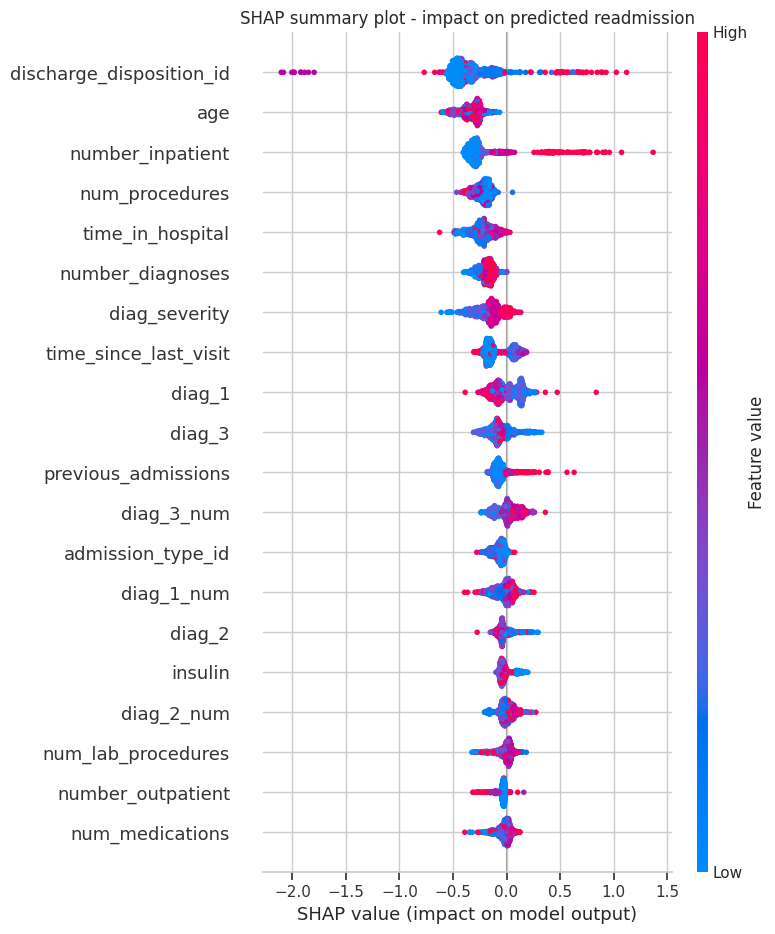

In [36]:
# SHAP summary (beeswarm) plot: each dot is one patient
try:
    shap.summary_plot(sv_global, X_shap_display, feature_names=feature_columns, max_display=20, show=False)
    plt.title("SHAP summary plot - impact on predicted readmission"); plt.tight_layout(); plt.show()
except Exception as err:
    print("SHAP summary plot could not be drawn:", err)

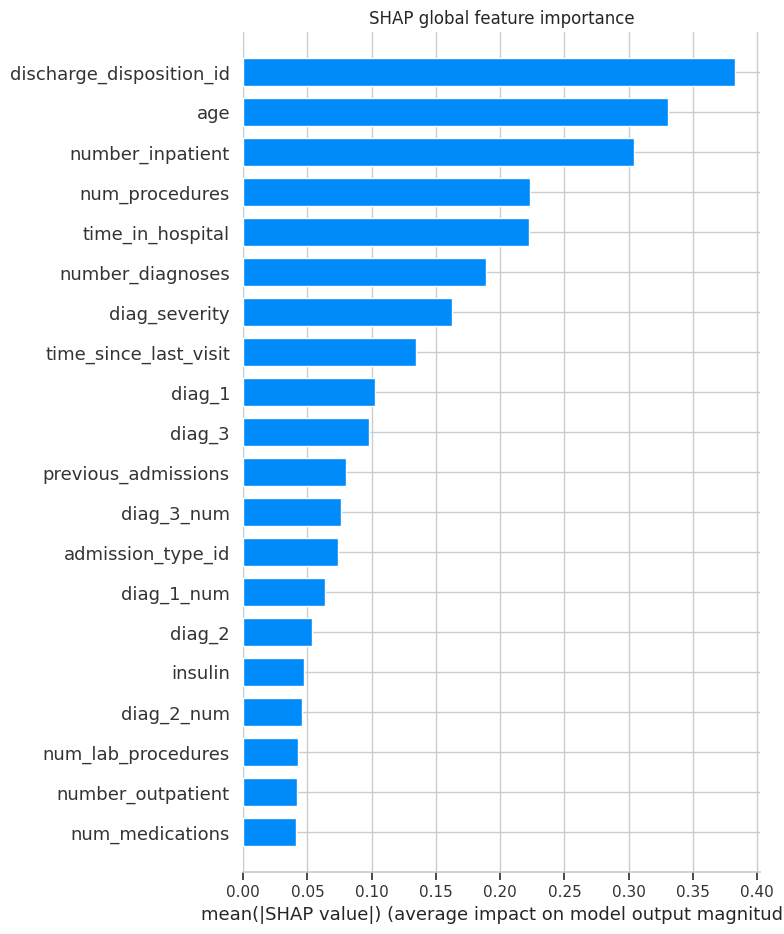

In [37]:
# SHAP feature-importance bar plot (mean absolute SHAP value)
try:
    shap.summary_plot(sv_global, X_shap_display, feature_names=feature_columns, plot_type="bar",
                      max_display=20, show=False)
    plt.title("SHAP global feature importance"); plt.tight_layout(); plt.show()
except Exception as err:
    print("SHAP bar plot could not be drawn:", err)

In [38]:
# Global feature importance ranking
global_importance = (pd.DataFrame({"feature": feature_columns,
                                   "mean_abs_shap": np.abs(sv_global).mean(axis=0),
                                   "mean_shap": sv_global.mean(axis=0)})
                     .sort_values("mean_abs_shap", ascending=False).reset_index(drop=True))
global_importance.index += 1
global_importance.index.name = "rank"
print("Global feature importance ranking (top 20):")
display(global_importance.head(20).round(5))

global_importance.to_csv("artifacts/global_shap_importance.csv", index=False)
shutil.make_archive("artifacts", "zip", "artifacts")      # refresh the zip with this file

Global feature importance ranking (top 20):


,feature,mean_abs_shap,mean_shap
rank,,,
1,discharge_disposition_id,0.38300,-0.33028
2,age,0.33069,-0.33069
3,number_inpatient,0.30437,-0.21491
4,num_procedures,0.22297,-0.22285
5,time_in_hospital,0.22243,-0.22230
6,number_diagnoses,0.18896,-0.18895
7,diag_severity,0.16249,-0.15694
8,time_since_last_visit,0.13445,-0.07204
9,diag_1,0.10220,-0.00368


'/content/artifacts.zip'

### Individual patient SHAP explanation
By default the test patient with the highest predicted risk is explained (an interesting case).
Set `PATIENT_INDEX` to any row number of the test set to explain another patient.
The same patient is used for LIME in Section 17.

In [39]:
PATIENT_INDEX = None      # None = highest-risk test patient, or an integer such as 0

idx_to_explain = int(np.argmax(proba_cal)) if PATIENT_INDEX is None else int(PATIENT_INDEX)
patient_result = analyze_encoded(X_test_enc[idx_to_explain], bundle, top_k=10)

print("Test patient #%d" % idx_to_explain)
print("Model prediction : %s" % patient_result["predicted_label"])
print("P(readmitted <30d) = %.4f | threshold = %.4f | actual outcome: %s"
      % (patient_result["proba_readmitted"], patient_result["threshold"], CLASS_NAMES[int(y_test[idx_to_explain])]))
print("\nTop 10 SHAP contributions (%s units):" % patient_result["shap_units"])
display(patient_result["shap_df"].head(10).round(4))

Test patient #17830
Model prediction : Readmitted within 30 days
P(readmitted <30d) = 0.8945 | threshold = 0.1198 | actual outcome: Readmitted within 30 days

Top 10 SHAP contributions (log-odds units):


,feature,patient_value,shap_value,direction
0,number_inpatient,6,0.9052,increases risk
1,diag_1,V58,0.8619,increases risk
2,previous_admissions,6,0.4855,increases risk
3,discharge_disposition_id,1,-0.2713,decreases risk
4,age,[60-70),-0.2429,decreases risk
5,diag_3_num,153,0.1819,increases risk
6,diag_3,153,0.1573,increases risk
7,number_diagnoses,5,-0.1545,decreases risk
8,time_since_last_visit,360,-0.1434,decreases risk
9,num_procedures,1,0.1357,increases risk


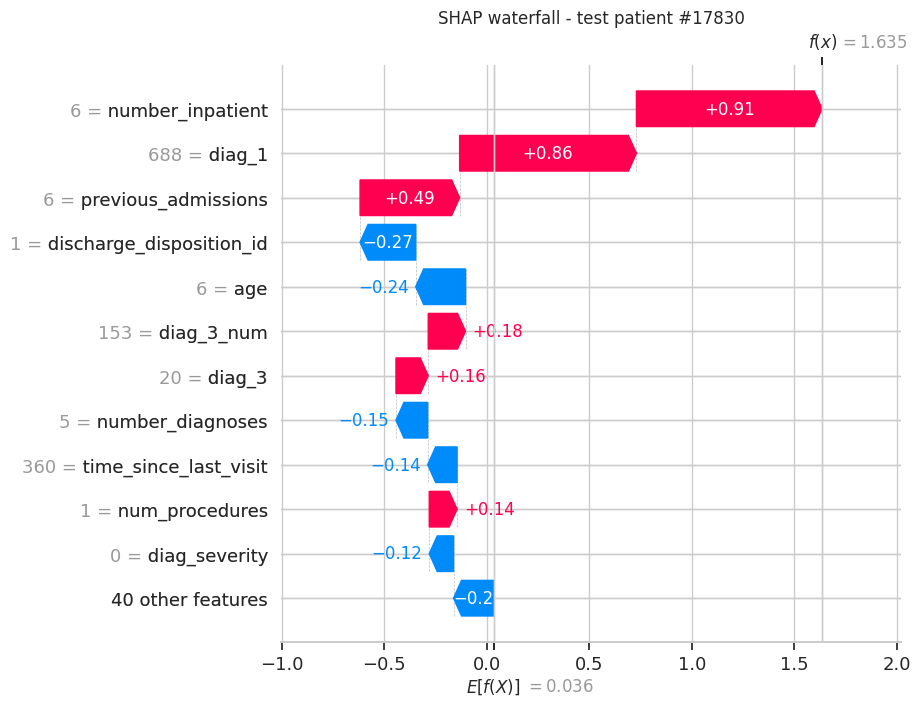

In [40]:
# SHAP waterfall plot for this patient
try:
    explanation_obj = shap.Explanation(values=patient_result["shap_values"],
                                       base_values=patient_result["shap_base"],
                                       data=patient_result["x_enc"], feature_names=feature_columns)
    shap.plots.waterfall(explanation_obj, max_display=12, show=False)
    plt.title("SHAP waterfall - test patient #%d" % idx_to_explain); plt.show()
except Exception as err:
    print("Waterfall plot unavailable (%s) - showing bar chart instead." % err)
    plot_contributions(patient_result["shap_df"], "shap_value", "SHAP contributions"); plt.show()

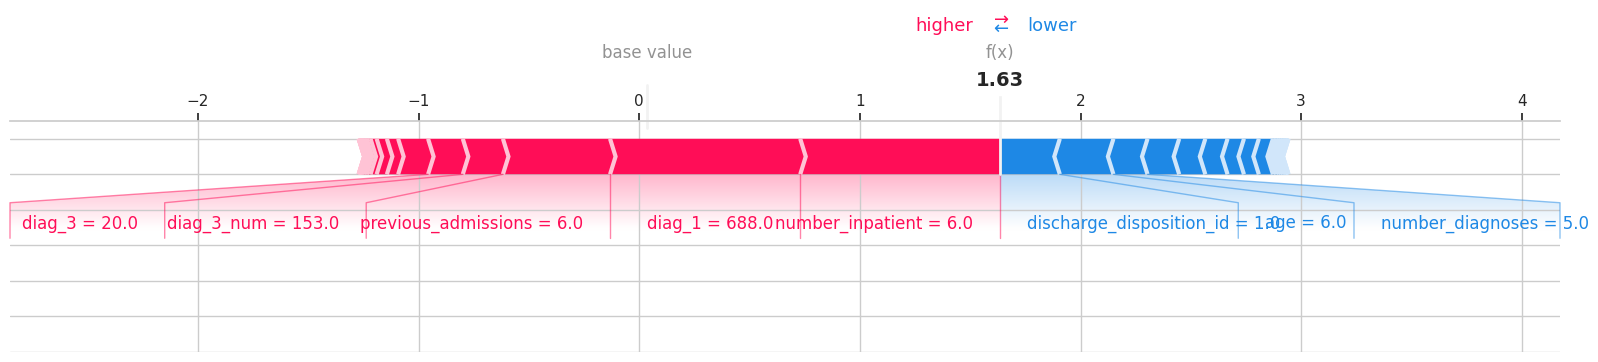

In [41]:
# SHAP force plot for this patient
try:
    shap.force_plot(patient_result["shap_base"], patient_result["shap_values"],
                    np.round(patient_result["x_enc"], 2), feature_names=feature_columns,
                    matplotlib=True, show=False)
    plt.show()
except Exception as err:
    print("Force plot not supported in this environment:", err)

## 17. Local explainability using LIME
**How LIME works:** it creates thousands of slightly changed copies of one patient, asks the model
for a prediction on each copy, and fits a simple weighted linear model to those predictions.
The weights of that simple model are the explanation: positive weights push towards readmission,
negative weights away from it.

**Why it is useful in healthcare:** it is model-agnostic (works with any classifier), it explains
one patient at a time, and it expresses the result as readable rules such as
`number_inpatient > 1.00`, which a clinician can check against the patient's record.

The prediction function given to LIME is the **calibrated model** applied to un-scaled encoded
features (the scaler is inside the model pipeline), so LIME explains exactly what is deployed.

LIME explanation for test patient #17830 - top 10 features


,feature,patient_value,lime_rule,lime_weight,direction
0,admission_type_id,3,1.00 < admission_type_id <= 3.00,0.0470,increases risk
1,number_inpatient,6,number_inpatient > 1.00,0.0428,increases risk
2,diag_2,287,diag_2=287,-0.0361,decreases risk
3,discharge_disposition_id,1,discharge_disposition_id <= 1.00,-0.0348,decreases risk
4,diag_1,V58,diag_1=V58,0.0328,increases risk
5,acarbose,No,acarbose=No,0.0323,increases risk
6,number_diagnoses,5,number_diagnoses <= 6.00,0.0293,increases risk
7,miglitol,No,miglitol=No,-0.0264,decreases risk
8,time_in_hospital,2,time_in_hospital <= 2.00,0.0221,increases risk
9,glipizide-metformin,No,glipizide-metformin=No,-0.0213,decreases risk


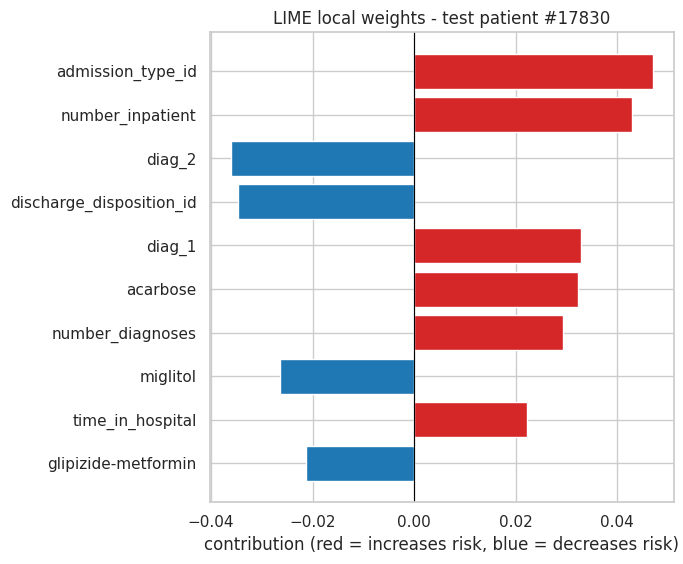

In [42]:
lime_exp = patient_result["lime_exp"]
lime_df = patient_result["lime_df"]

print("LIME explanation for test patient #%d - top 10 features" % idx_to_explain)
display(lime_df[["feature", "patient_value", "lime_rule", "lime_weight", "direction"]].round(4))

try:
    lime_exp.show_in_notebook(show_table=True, show_all=False)
except Exception as err:
    print("Interactive LIME view unavailable:", err)

plot_contributions(lime_df, "lime_weight", "LIME local weights - test patient #%d" % idx_to_explain)
plt.show()

## 18. SHAP and LIME comparison
Both methods explain the same patient, but they answer slightly different questions:

- **SHAP** distributes the model's actual output among the features using Shapley values from the
  model's internal structure (here: the tuned model before calibration).
- **LIME** fits a local linear approximation around the patient using random perturbations of the
  calibrated model, and discretizes numerical features into ranges.

Their numbers are therefore on **different scales and are not directly comparable**. What can be
compared is the *ranking* of features and the *direction* of their effect:

- **Feature overlap / Jaccard similarity** = shared top-10 features / all features in either top-10 list.
- **Sign agreement** = share of the common features where both methods give the same direction.

Disagreement does not mean one method is wrong. It usually comes from LIME's random sampling,
its linear approximation of a non-linear model, correlated features (for example `num_medications`
and `medication_load` are identical, so credit can be split differently), and the different baselines.

Top 10 SHAP features: ['number_inpatient', 'diag_1', 'previous_admissions', 'discharge_disposition_id', 'age', 'diag_3_num', 'diag_3', 'number_diagnoses', 'time_since_last_visit', 'num_procedures']
Top 10 LIME features: ['admission_type_id', 'number_inpatient', 'diag_2', 'discharge_disposition_id', 'diag_1', 'acarbose', 'number_diagnoses', 'miglitol', 'time_in_hospital', 'glipizide-metformin']

Feature overlap (4): ['number_inpatient', 'diag_1', 'discharge_disposition_id', 'number_diagnoses']
Jaccard similarity of the two top-10 lists: 0.250
Sign agreement on the common features: 75%

Ranking and direction, side by side:


,feature,shap_rank,lime_rank,shap_direction,lime_direction
0,number_inpatient,1.0,2.0,increases risk,increases risk
1,diag_1,2.0,5.0,increases risk,increases risk
2,previous_admissions,3.0,NaN,increases risk,outside top 10
3,discharge_disposition_id,4.0,4.0,decreases risk,decreases risk
4,age,5.0,NaN,decreases risk,outside top 10
5,diag_3_num,6.0,NaN,increases risk,outside top 10
6,diag_3,7.0,NaN,increases risk,outside top 10
7,number_diagnoses,8.0,7.0,decreases risk,increases risk
8,time_since_last_visit,9.0,NaN,decreases risk,outside top 10
9,num_procedures,10.0,NaN,increases risk,outside top 10


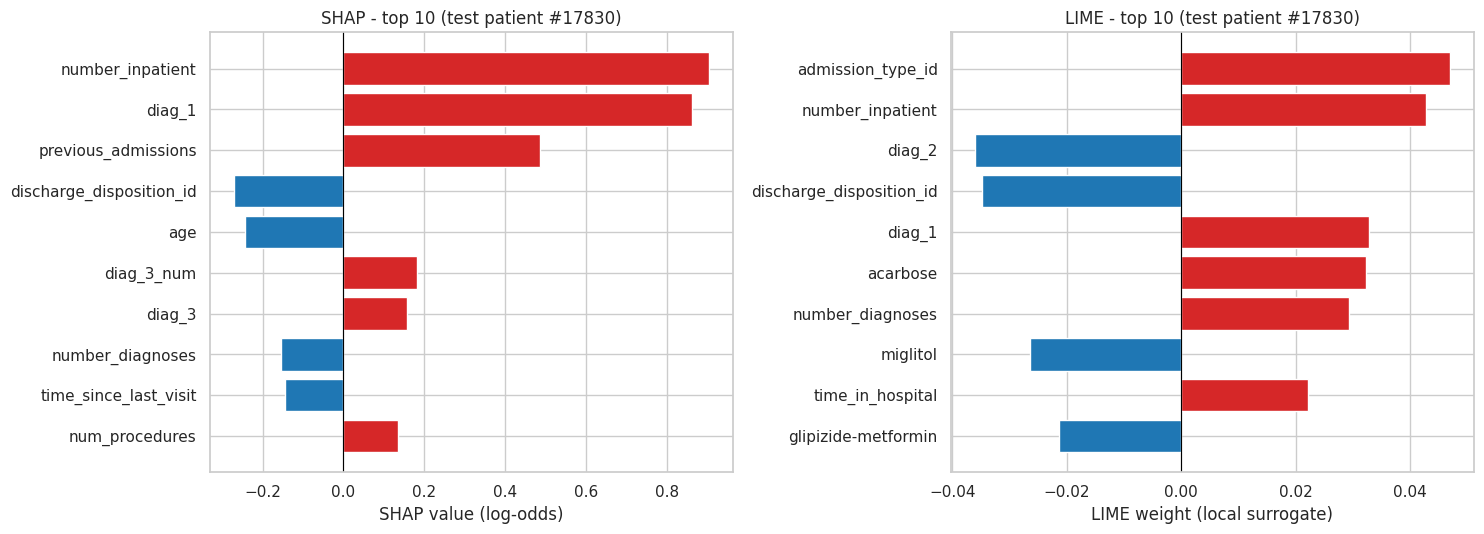

In [43]:
compare_df, agreement = patient_result["compare_df"], patient_result["agreement"]

print("Top 10 SHAP features:", list(patient_result["shap_df"]["feature"].head(10)))
print("Top 10 LIME features:", list(lime_df["feature"]))
print("\nFeature overlap (%d): %s" % (len(agreement["common_features"]), agreement["common_features"]))
print("Jaccard similarity of the two top-10 lists: %.3f" % agreement["jaccard"])
if agreement["sign_agreement"] is None:
    print("Sign agreement: not applicable (no common features)")
else:
    print("Sign agreement on the common features: %.0f%%" % (100 * agreement["sign_agreement"]))
print("\nRanking and direction, side by side:")
display(compare_df)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
plot_contributions(patient_result["shap_df"], "shap_value", "SHAP - top 10 (test patient #%d)" % idx_to_explain,
                   ax=axes[0], xlabel="SHAP value (%s)" % patient_result["shap_units"])
plot_contributions(lime_df, "lime_weight", "LIME - top 10 (test patient #%d)" % idx_to_explain,
                   ax=axes[1], xlabel="LIME weight (local surrogate)")
plt.tight_layout(); plt.show()

## 19. LLM-based natural-language explanation
The LLM turns the technical output into a short text for a healthcare professional. It is only an
**explanation writer** - it never makes or changes the prediction.

**What is sent to the LLM** (and nothing else): the predicted class, the probability, the threshold,
the top SHAP features with their contributions, the top LIME rules with their weights, and the
SHAP/LIME agreement. No patient identifiers exist in the data (`encounter_id` and `patient_nbr` were dropped).

**Safeguards**
- The system prompt forbids new medical facts, diagnoses, treatments, or changing any number.
- The returned text is checked: all seven sections must be present and the probability and
  prediction must match the model exactly. If a check fails, the LLM text is discarded.
- If there is no API key, no internet, or the API fails, a **template explanation** with the same
  seven sections is produced, so the notebook always runs.

**API key setup (Google Gemini, free tier)**
1. Create a key at https://aistudio.google.com/app/apikey
2. In Colab, click the **key icon** (Secrets) in the left sidebar -> *Add new secret*.
3. Name: `GEMINI_API_KEY`, Value: your key, and switch on *Notebook access*.

The key is read from Colab Secrets (or an environment variable). It is never written in the notebook.
The SDK (`google-genai`) was installed in Section 1. If a model name is retired, edit `LLM_MODELS` below.

In [44]:
%%writefile cdss_llm.py
"""cdss_llm.py - turns the ML prediction + SHAP/LIME evidence into plain language.

The LLM is ONLY an explanation writer. The prediction and probability always come
from the trained model; if the LLM is unavailable or its text fails the checks,
a deterministic template explanation is returned instead."""
import json
import os

DEFAULT_MODELS = ["gemini-3.6-flash", "gemini-3.5-flash", "gemini-2.5-flash"]  # tried in order

SECTION_TITLES = [
    "Model Prediction",
    "Prediction Probability",
    "Important Risk-Increasing Factors",
    "Important Risk-Reducing Factors",
    "SHAP and LIME Explanation",
    "Human-Readable Summary",
    "Clinical Caution",
]

CAUTION = ("This is the output of a machine-learning model trained on historical hospital data. "
           "It is decision support only: it is not a diagnosis, it does not recommend treatment, "
           "and it must not replace the judgement of a qualified healthcare professional.")

SYSTEM_PROMPT = """You are the explanation component of a clinical decision support system that
predicts 30-day hospital readmission for diabetes patients. A trained machine-learning model has
ALREADY made the prediction. Your only job is to explain the supplied evidence in clear language
for a healthcare professional.

Strict rules:
1. Use ONLY the facts in the JSON evidence. Do not add medical knowledge, diagnoses, causes,
   treatments, medication advice or recommendations of any kind.
2. Never change, round differently, or re-estimate the prediction, probability or threshold.
   Copy "prediction", "probability_text" and "threshold_text" exactly as given.
3. Describe features as factors that pushed the MODEL'S prediction up or down. Do not claim
   they cause readmission.
4. SHAP and LIME numbers are on different scales: compare direction and ranking only.
5. Write exactly these seven numbered sections, with these titles, in this order:
   1. Model Prediction
   2. Prediction Probability
   3. Important Risk-Increasing Factors
   4. Important Risk-Reducing Factors
   5. SHAP and LIME Explanation
   6. Human-Readable Summary
   7. Clinical Caution
6. Keep it under 300 words. Plain text, short sentences, no tables."""


def build_llm_payload(result, top_n=6):
    """Only the prediction and the top explanation evidence - no IDs, no full patient record."""
    shap_rows = result["shap_df"].head(top_n)
    lime_rows = result["lime_df"].reindex(
        result["lime_df"]["lime_weight"].abs().sort_values(ascending=False).index).head(top_n)
    return {
        "prediction": result["predicted_label"],
        "probability_text": "%.1f%%" % (100 * result["proba_readmitted"]),
        "threshold_text": "%.1f%%" % (100 * result["threshold"]),
        "decision_rule": "classified as readmitted when probability >= threshold",
        "model": result["model_name"],
        "shap_units": result["shap_units"],
        "shap_top_features": [
            {"feature": r.feature, "patient_value": str(r.patient_value),
             "contribution": round(float(r.shap_value), 4), "direction": r.direction}
            for r in shap_rows.itertuples()],
        "lime_top_features": [
            {"feature": r.feature, "rule": r.lime_rule,
             "weight": round(float(r.lime_weight), 4), "direction": r.direction}
            for r in lime_rows.itertuples()],
        "shap_lime_agreement": {
            "features_in_both_top_lists": result["agreement"]["common_features"],
            "same_direction_in_both": result["agreement"]["same_direction_features"],
            "jaccard_overlap": result["agreement"]["jaccard"],
        },
    }


def _join(items):
    return "; ".join(items) if items else "none among the top factors"


def template_explanation(payload):
    """Deterministic fallback with the same seven sections (no LLM needed)."""
    up = ["%s = %s" % (f["feature"], f["patient_value"])
          for f in payload["shap_top_features"] if f["contribution"] > 0]
    down = ["%s = %s" % (f["feature"], f["patient_value"])
            for f in payload["shap_top_features"] if f["contribution"] < 0]
    lime_up = [f["rule"] for f in payload["lime_top_features"] if f["weight"] > 0]
    lime_down = [f["rule"] for f in payload["lime_top_features"] if f["weight"] < 0]
    agree = payload["shap_lime_agreement"]
    side = "at or above" if payload["prediction"].startswith("Readmitted") else "below"
    lines = [
        "1. Model Prediction",
        "The model classifies this patient as: %s." % payload["prediction"],
        "",
        "2. Prediction Probability",
        "Estimated probability of readmission within 30 days: %s. This is %s the decision "
        "threshold of %s." % (payload["probability_text"], side, payload["threshold_text"]),
        "",
        "3. Important Risk-Increasing Factors",
        "According to SHAP, these pushed the prediction towards readmission: %s." % _join(up),
        "",
        "4. Important Risk-Reducing Factors",
        "According to SHAP, these pushed the prediction away from readmission: %s." % _join(down),
        "",
        "5. SHAP and LIME Explanation",
        "LIME rules raising the prediction: %s. LIME rules lowering it: %s. "
        "Features in the top list of both methods: %s (overlap score %.2f); of these, both "
        "methods give the same direction for: %s. The two methods use different scales, so "
        "only ranking and direction are compared."
        % (_join(lime_up), _join(lime_down), _join(agree["features_in_both_top_lists"]),
           agree["jaccard_overlap"], _join(agree["same_direction_in_both"])),
        "",
        "6. Human-Readable Summary",
        "Based on the %s model, this patient is predicted as '%s' with a readmission "
        "probability of %s. The factors listed above describe what influenced the model, "
        "not what causes readmission."
        % (payload["model"], payload["prediction"], payload["probability_text"]),
        "",
        "7. Clinical Caution",
        CAUTION,
    ]
    return "\n".join(lines)


def get_api_key():
    """Colab Secrets first, then environment variables. Never hardcode the key."""
    for name in ("GEMINI_API_KEY", "GOOGLE_API_KEY"):
        try:
            from google.colab import userdata
            key = userdata.get(name)
            if key:
                return key
        except Exception:
            pass
        if os.environ.get(name):
            return os.environ[name]
    return None


def call_gemini(payload, api_key, models=None, temperature=0.2):
    from google import genai
    from google.genai import types
    client = genai.Client(api_key=api_key)
    prompt = ("Explain this model output. Evidence (JSON):\n"
              + json.dumps(payload, indent=2, default=str))
    last_error = None
    for name in (models or DEFAULT_MODELS):
        try:
            resp = client.models.generate_content(
                model=name, contents=prompt,
                config=types.GenerateContentConfig(system_instruction=SYSTEM_PROMPT,
                                                   temperature=temperature))
            text = (getattr(resp, "text", None) or "").strip()
            if text:
                return text, name
            last_error = "empty response from " + name
        except Exception as err:          # wrong model name, quota, network ...
            last_error = "%s: %s" % (name, err)
    raise RuntimeError(str(last_error))


def check_llm_text(text, payload):
    """Reject LLM text that drops sections or alters the model's numbers/label."""
    low = text.lower()
    problems = [t for t in SECTION_TITLES if t.lower() not in low]
    if payload["probability_text"] not in text:
        problems.append("probability changed or missing")
    if payload["prediction"].lower() not in low:
        problems.append("prediction label changed or missing")
    return problems


def generate_explanation(result, api_key=None, models=None, use_llm=True):
    """Returns {"text", "source", "note", "payload"}; never raises."""
    payload = build_llm_payload(result)
    note = "LLM disabled - template explanation used."
    if use_llm:
        key = api_key or get_api_key()
        if not key:
            note = "No API key found - template explanation used."
        else:
            try:
                text, used = call_gemini(payload, key, models)
                problems = check_llm_text(text, payload)
                if not problems:
                    return {"text": text, "source": "LLM (%s)" % used, "note": "", "payload": payload}
                note = "LLM text failed safety checks (%s) - template used." % ", ".join(problems)
            except Exception as err:
                note = "LLM unavailable (%s) - template explanation used." % str(err)[:200]
    return {"text": template_explanation(payload), "source": "template", "note": note,
            "payload": payload}

Writing cdss_llm.py


In [45]:
import cdss_llm
importlib.reload(cdss_llm)
from cdss_llm import generate_explanation, build_llm_payload, get_api_key

LLM_MODELS = ["gemini-3.6-flash", "gemini-3.5-flash", "gemini-2.5-flash"]   # tried in this order
USE_LLM = True

print("API key found:", bool(get_api_key()))
print("\nEvidence that will be sent to the LLM for test patient #%d:" % idx_to_explain)
print(json.dumps(build_llm_payload(patient_result), indent=2, default=str))

API key found: False

Evidence that will be sent to the LLM for test patient #17830:
{
  "prediction": "Readmitted within 30 days",
  "probability_text": "89.5%",
  "threshold_text": "12.0%",
  "decision_rule": "classified as readmitted when probability >= threshold",
  "model": "XGBoost",
  "shap_units": "log-odds",
  "shap_top_features": [
    {
      "feature": "number_inpatient",
      "patient_value": "6",
      "contribution": 0.9052,
      "direction": "increases risk"
    },
    {
      "feature": "diag_1",
      "patient_value": "V58",
      "contribution": 0.8619,
      "direction": "increases risk"
    },
    {
      "feature": "previous_admissions",
      "patient_value": "6",
      "contribution": 0.4855,
      "direction": "increases risk"
    },
    {
      "feature": "discharge_disposition_id",
      "patient_value": "1",
      "contribution": -0.2713,
      "direction": "decreases risk"
    },
    {
      "feature": "age",
      "patient_value": "[60-70)",
      "contr

In [46]:
llm_output = generate_explanation(patient_result, models=LLM_MODELS, use_llm=USE_LLM)

print("Explanation source:", llm_output["source"])
if llm_output["note"]:
    print("Note:", llm_output["note"])
print("-" * 80)
print(llm_output["text"])

Explanation source: template
Note: No API key found - template explanation used.
--------------------------------------------------------------------------------
1. Model Prediction
The model classifies this patient as: Readmitted within 30 days.

2. Prediction Probability
Estimated probability of readmission within 30 days: 89.5%. This is at or above the decision threshold of 12.0%.

3. Important Risk-Increasing Factors
According to SHAP, these pushed the prediction towards readmission: number_inpatient = 6; diag_1 = V58; previous_admissions = 6; diag_3_num = 153.

4. Important Risk-Reducing Factors
According to SHAP, these pushed the prediction away from readmission: discharge_disposition_id = 1; age = [60-70).

5. SHAP and LIME Explanation
LIME rules raising the prediction: 1.00 < admission_type_id <= 3.00; number_inpatient > 1.00; diag_1=V58; acarbose=No. LIME rules lowering it: diag_2=287; discharge_disposition_id <= 1.00. Features in the top list of both methods: number_inpatient

## 20. Clinical decision support system
`run_cdss(patient)` is the complete pipeline for one patient record:

raw inputs -> same preprocessing and feature engineering as training -> **saved calibrated model**
-> probability and class at the chosen threshold -> SHAP -> LIME -> comparison -> LLM explanation.

The output is a model prediction that supports a clinician's decision. It is **not** a confirmed
diagnosis and it does not replace a healthcare professional.

In [47]:
def run_cdss(patient, use_llm=True, show_plots=True):
    """Full decision-support report for one raw patient record (a dict)."""
    res = analyze_patient(patient, bundle, top_k=10)
    exp = generate_explanation(res, models=LLM_MODELS, use_llm=use_llm)

    display(Markdown("### Patient input summary"))
    display(pd.DataFrame({"value": pd.Series(patient).astype(str)}))
    for col, vals in res["unseen_categories"].items():
        print("Note: %s for '%s' was not seen in training - the most common training value was used." % (vals, col))

    display(Markdown("### Model prediction"))
    print("Predicted class                           : %d - %s" % (res["predicted_class"], res["predicted_label"]))
    print("Probability of NOT being readmitted       : %.4f" % res["proba_not_readmitted"])
    print("Probability of readmission within 30 days : %.4f" % res["proba_readmitted"])
    print("Decision threshold                        : %.4f" % res["threshold"])
    print("Risk label                                : %s"
          % ("Higher predicted risk (at or above threshold)" if res["predicted_class"] else "Lower predicted risk (below threshold)"))

    display(Markdown("### SHAP explanation (top 10)"))
    display(res["shap_df"].head(10).round(4))
    display(Markdown("### LIME explanation (top 10)"))
    display(res["lime_df"][["feature", "patient_value", "lime_rule", "lime_weight", "direction"]].round(4))

    display(Markdown("### Combined explanation (SHAP + LIME)"))
    a = res["agreement"]
    print("Features in both top-10 lists:", a["common_features"])
    print("Jaccard similarity: %.3f | Same direction in both methods: %s" % (a["jaccard"], a["same_direction_features"]))
    if show_plots:
        fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
        plot_contributions(res["shap_df"], "shap_value", "SHAP - this patient", ax=axes[0],
                           xlabel="SHAP value (%s)" % res["shap_units"])
        plot_contributions(res["lime_df"], "lime_weight", "LIME - this patient", ax=axes[1],
                           xlabel="LIME weight (local surrogate)")
        plt.tight_layout(); plt.show()

    display(Markdown("### Natural-language explanation (source: %s)" % exp["source"]))
    if exp["note"]:
        print("Note:", exp["note"])
    print(exp["text"])
    res["explanation"] = exp
    return res

# Self-test: raw test-set records sent through the deployment path must give exactly the
# same probabilities as the training pipeline (proves preprocessing is consistent).
check_rows = X_test_df.iloc[:25]
via_cdss = [analyze_patient(r.to_dict(), bundle)["proba_readmitted"] for _, r in check_rows.iterrows()]
assert np.allclose(via_cdss, proba_cal[:25]), "Training and inference preprocessing differ!"
print("Self-test passed: deployment path reproduces the training-pipeline probabilities for 25 test patients.")

Self-test passed: deployment path reproduces the training-pipeline probabilities for 25 test patients.


## 21. New patient prediction
Fill in the form on the right of the cell (Colab shows the fields), then run the cell.
Any field that is not on the form (the other medication columns) is set to its most common
training value. Unseen category values are handled safely and reported.

### Patient input summary

,value
race,Caucasian
gender,Female
age,[70-80)
diag_1,428
diag_2,250.02
diag_3,401
max_glu_serum,None
A1Cresult,>8
metformin,No
repaglinide,No


### Model prediction

Predicted class                           : 1 - Readmitted within 30 days
Probability of NOT being readmitted       : 0.8687
Probability of readmission within 30 days : 0.1313
Decision threshold                        : 0.1198
Risk label                                : Higher predicted risk (at or above threshold)


### SHAP explanation (top 10)

,feature,patient_value,shap_value,direction
0,discharge_disposition_id,1,-0.3206,decreases risk
1,age,[70-80),-0.2704,decreases risk
2,diag_3,401,-0.2513,decreases risk
3,number_diagnoses,9,-0.1819,decreases risk
4,num_procedures,1,-0.1811,decreases risk
5,A1Cresult,>8,-0.1753,decreases risk
6,time_since_last_visit,135,0.1575,increases risk
7,time_in_hospital,5,-0.1062,decreases risk
8,number_inpatient,2,-0.0961,decreases risk
9,diag_severity,9,-0.0719,decreases risk


### LIME explanation (top 10)

,feature,patient_value,lime_rule,lime_weight,direction
0,acarbose,No,acarbose=No,0.0457,increases risk
1,number_inpatient,2,number_inpatient > 1.00,0.0414,increases risk
2,number_diagnoses,9,8.00 < number_diagnoses <= 9.00,-0.0382,decreases risk
3,discharge_disposition_id,1,discharge_disposition_id <= 1.00,-0.0334,decreases risk
4,admission_type_id,1,admission_type_id <= 1.00,-0.0303,decreases risk
5,diag_severity,9,diag_severity > 6.25,0.0272,increases risk
6,miglitol,No,miglitol=No,-0.0233,decreases risk
7,admission_source_id,7,1.00 < admission_source_id <= 7.00,0.0173,increases risk
8,num_procedures,1,0.00 < num_procedures <= 1.00,-0.0157,decreases risk
9,diag_3,401,diag_3=401,-0.0137,decreases risk


### Combined explanation (SHAP + LIME)

Features in both top-10 lists: ['discharge_disposition_id', 'diag_3', 'number_diagnoses', 'num_procedures', 'number_inpatient', 'diag_severity']
Jaccard similarity: 0.429 | Same direction in both methods: ['discharge_disposition_id', 'diag_3', 'number_diagnoses', 'num_procedures']


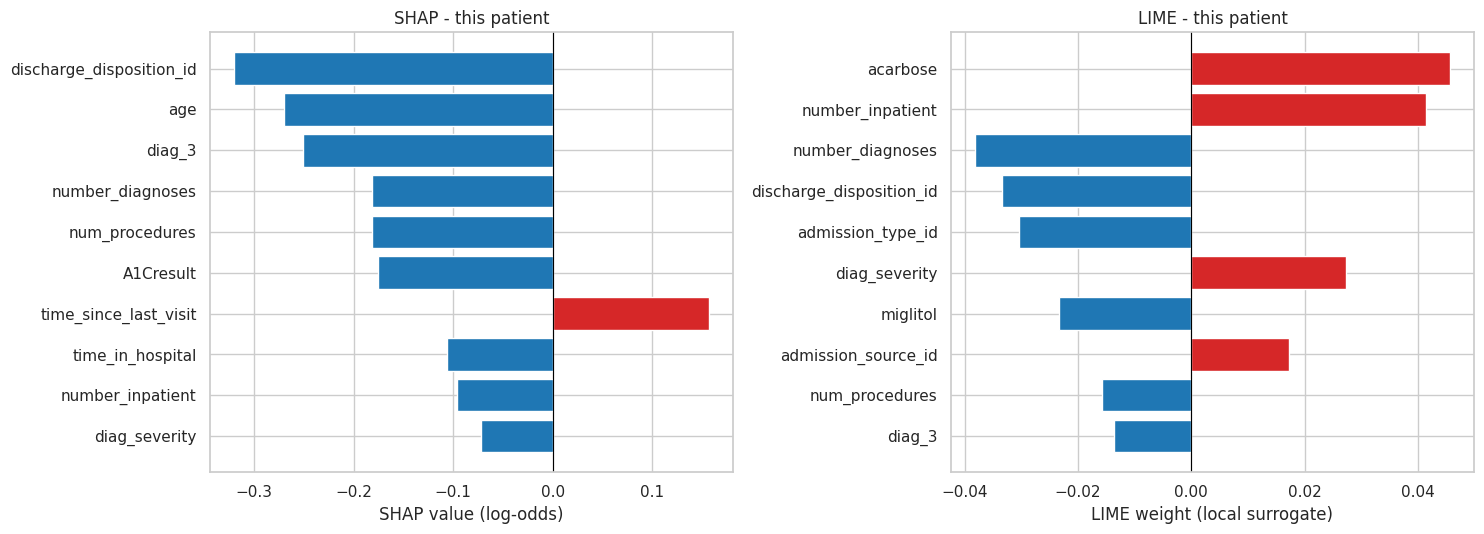

### Natural-language explanation (source: template)

Note: No API key found - template explanation used.
1. Model Prediction
The model classifies this patient as: Readmitted within 30 days.

2. Prediction Probability
Estimated probability of readmission within 30 days: 13.1%. This is at or above the decision threshold of 12.0%.

3. Important Risk-Increasing Factors
According to SHAP, these pushed the prediction towards readmission: none among the top factors.

4. Important Risk-Reducing Factors
According to SHAP, these pushed the prediction away from readmission: discharge_disposition_id = 1; age = [70-80); diag_3 = 401; number_diagnoses = 9; num_procedures = 1; A1Cresult = >8.

5. SHAP and LIME Explanation
LIME rules raising the prediction: acarbose=No; number_inpatient > 1.00; diag_severity > 6.25. LIME rules lowering it: 8.00 < number_diagnoses <= 9.00; discharge_disposition_id <= 1.00; admission_type_id <= 1.00. Features in the top list of both methods: discharge_disposition_id; diag_3; number_diagnoses; num_procedures; number_inpati

In [48]:
race = "Caucasian"  #@param ["Caucasian", "AfricanAmerican", "Hispanic", "Asian", "Other"]
gender = "Female"  #@param ["Female", "Male"]
age = "[70-80)"  #@param ["[0-10)", "[10-20)", "[20-30)", "[30-40)", "[40-50)", "[50-60)", "[60-70)", "[70-80)", "[80-90)", "[90-100)"]
admission_type_id = 1  #@param {type:"integer"}
discharge_disposition_id = 1  #@param {type:"integer"}
admission_source_id = 7  #@param {type:"integer"}
time_in_hospital = 5  #@param {type:"integer"}
num_lab_procedures = 45  #@param {type:"integer"}
num_procedures = 1  #@param {type:"integer"}
num_medications = 16  #@param {type:"integer"}
number_outpatient = 0  #@param {type:"integer"}
number_emergency = 1  #@param {type:"integer"}
number_inpatient = 2  #@param {type:"integer"}
number_diagnoses = 9  #@param {type:"integer"}
max_glu_serum = "None"  #@param ["None", "Norm", ">200", ">300"]
A1Cresult = ">8"  #@param ["None", "Norm", ">7", ">8"]
insulin = "Up"  #@param ["No", "Steady", "Up", "Down"]
diag_1 = "428"  #@param {type:"string"}
diag_2 = "250.02"  #@param {type:"string"}
diag_3 = "401"  #@param {type:"string"}
change = "Ch"  #@param ["Ch", "No"]
diabetesMed = "Yes"  #@param ["Yes", "No"]

new_patient = dict(bundle["state"]["impute_values"])     # defaults for fields not on the form
new_patient.update({
    "race": race, "gender": gender, "age": age,
    "admission_type_id": admission_type_id, "discharge_disposition_id": discharge_disposition_id,
    "admission_source_id": admission_source_id, "time_in_hospital": time_in_hospital,
    "num_lab_procedures": num_lab_procedures, "num_procedures": num_procedures,
    "num_medications": num_medications, "number_outpatient": number_outpatient,
    "number_emergency": number_emergency, "number_inpatient": number_inpatient,
    "number_diagnoses": number_diagnoses, "max_glu_serum": max_glu_serum, "A1Cresult": A1Cresult,
    "insulin": insulin, "diag_1": diag_1, "diag_2": diag_2, "diag_3": diag_3,
    "change": change, "diabetesMed": diabetesMed,
})

new_patient_result = run_cdss(new_patient, use_llm=USE_LLM)

## 22. Final application (Streamlit)
The next cell writes `app.py`, a six-page dashboard:

1. Project Overview - 2. Patient Information - 3. Prediction Results - 4. Explainable AI -
5. LLM Explanation - 6. Clinical Decision Support

The app imports the same `cdss_utils.py`, `cdss_xai.py` and `cdss_llm.py` modules used above and
loads the saved artifacts, so it gives the same answers as this notebook.

In [49]:
%%writefile app.py
"""Streamlit front-end: Explainable AI Clinical Decision Support System
30-day readmission prediction for Type 2 Diabetes patients.
Run locally with:  streamlit run app.py"""
import os

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import streamlit as st

from cdss_llm import CAUTION, generate_explanation
from cdss_xai import CLASS_NAMES, analyze_patient, load_bundle, plot_contributions

st.set_page_config(page_title="Diabetes Readmission CDSS", page_icon="🏥", layout="wide")

ARTIFACTS_DIR = os.path.join(os.path.dirname(os.path.abspath(__file__)), "artifacts")
PAGES = ["1. Project Overview", "2. Patient Information", "3. Prediction Results",
         "4. Explainable AI", "5. LLM Explanation", "6. Clinical Decision Support"]
MED_COLS = ["metformin", "repaglinide", "nateglinide", "chlorpropamide", "glimepiride",
            "glipizide", "glyburide", "pioglitazone", "rosiglitazone", "acarbose",
            "glyburide-metformin"]


@st.cache_resource(show_spinner="Loading model and explainers ...")
def get_bundle():
    return load_bundle(ARTIFACTS_DIR)


def get_llm_key():
    try:
        if "GEMINI_API_KEY" in st.secrets:
            return st.secrets["GEMINI_API_KEY"]
    except Exception:
        pass
    return os.environ.get("GEMINI_API_KEY") or os.environ.get("GOOGLE_API_KEY")


def need_result():
    if "result" not in st.session_state:
        st.info("No prediction yet. Open **2. Patient Information**, fill the form and press "
                "**Predict readmission risk**.")
        return None
    return st.session_state["result"]


def pick(label, col, ui, default=None):
    options = ui["categorical"][col]
    idx = options.index(default) if default in options else 0
    return st.selectbox(label, options, index=idx)


def number(label, col, ui):
    r = ui["numeric"][col]
    return st.number_input(label, min_value=0, max_value=int(max(r["max"], 1)),
                           value=int(r["median"]), step=1)


bundle = get_bundle()
config, state = bundle["config"], bundle["state"]
ui = config["ui_options"]

st.sidebar.title("🏥 Readmission CDSS")
page = st.sidebar.radio("Navigation", PAGES)
st.sidebar.markdown("---")
st.sidebar.caption("Model: %s  \nDecision threshold: %.3f" % (bundle["model_name"], bundle["threshold"]))
st.sidebar.warning("Decision support only. Not a medical diagnosis.")

# ------------------------------------------------------------------ PAGE 1
if page == PAGES[0]:
    st.title("Explainable AI-Based Clinical Decision Support System for Diabetes")
    st.subheader("Predicting Type 2 Diabetes patient readmission within 30 days of discharge")
    st.markdown("""
**Objective.** Estimate whether a diabetes patient is likely to be readmitted to hospital within
30 days of discharge, and explain *why* the model gave that estimate.

**How the system works**
1. Patient details are entered on the *Patient Information* page.
2. The same preprocessing and feature engineering used in training are applied.
3. A calibrated **%s** model returns the probability of readmission within 30 days.
4. **SHAP** and **LIME** show which features pushed the prediction up or down.
5. An **LLM** rewrites that evidence in plain language (a template is used if the LLM is unavailable).

**Data.** Diabetes 130-US Hospitals dataset (UCI Machine Learning Repository), 1999-2008,
about 101,766 hospital encounters.
""" % bundle["model_name"])
    m = config.get("test_metrics", {})
    if m:
        st.markdown("**Held-out test-set performance of the deployed model**")
        cols = st.columns(len(m))
        for c, (k, v) in zip(cols, m.items()):
            c.metric(k, "%.3f" % v)
    st.warning(CAUTION)

# ------------------------------------------------------------------ PAGE 2
elif page == PAGES[1]:
    st.title("Patient Information")
    st.caption("Enter the encounter details. Fields not shown use the most common training value.")
    with st.form("patient_form"):
        c1, c2, c3 = st.columns(3)
        with c1:
            st.markdown("**Demographics & admission**")
            race = pick("Race", "race", ui, "Caucasian")
            gender = pick("Gender", "gender", ui, "Female")
            age = pick("Age group", "age", ui, "[60-70)")
            adm_type = st.selectbox("Admission type ID", ui["ids"]["admission_type_id"])
            disch = st.selectbox("Discharge disposition ID", ui["ids"]["discharge_disposition_id"])
            adm_src = st.selectbox("Admission source ID", ui["ids"]["admission_source_id"],
                                   index=ui["ids"]["admission_source_id"].index(7)
                                   if 7 in ui["ids"]["admission_source_id"] else 0)
        with c2:
            st.markdown("**Hospital stay & history**")
            time_in_hospital = number("Time in hospital (days)", "time_in_hospital", ui)
            num_lab = number("Number of lab procedures", "num_lab_procedures", ui)
            num_proc = number("Number of procedures", "num_procedures", ui)
            num_meds = number("Number of medications", "num_medications", ui)
            n_out = number("Outpatient visits (past year)", "number_outpatient", ui)
            n_emg = number("Emergency visits (past year)", "number_emergency", ui)
            n_inp = number("Inpatient visits (past year)", "number_inpatient", ui)
            n_diag = number("Number of diagnoses", "number_diagnoses", ui)
        with c3:
            st.markdown("**Diagnoses, tests & medication**")
            diag_1 = st.text_input("Primary diagnosis (ICD-9)", "428")
            diag_2 = st.text_input("Secondary diagnosis (ICD-9)", "250")
            diag_3 = st.text_input("Tertiary diagnosis (ICD-9)", "401")
            glu = pick("Max glucose serum", "max_glu_serum", ui, "None")
            a1c = pick("HbA1c result", "A1Cresult", ui, "None")
            insulin = pick("Insulin", "insulin", ui, "No")
            change = pick("Change in medications", "change", ui, "No")
            diabetes_med = pick("Diabetes medication prescribed", "diabetesMed", ui, "Yes")
            other_meds = st.multiselect("Other diabetes medicines taken (steady dose)",
                                        [m for m in MED_COLS if m in state["raw_columns"]])
        use_llm = st.checkbox("Generate LLM explanation", value=True)
        submitted = st.form_submit_button("Predict readmission risk", type="primary")

    if submitted:
        patient = dict(state["impute_values"])          # defaults = most common training values
        patient.update({
            "race": race, "gender": gender, "age": age,
            "admission_type_id": adm_type, "discharge_disposition_id": disch,
            "admission_source_id": adm_src, "time_in_hospital": time_in_hospital,
            "num_lab_procedures": num_lab, "num_procedures": num_proc,
            "num_medications": num_meds, "number_outpatient": n_out,
            "number_emergency": n_emg, "number_inpatient": n_inp, "number_diagnoses": n_diag,
            "max_glu_serum": glu, "A1Cresult": a1c, "insulin": insulin,
            "diag_1": diag_1.strip(), "diag_2": diag_2.strip(), "diag_3": diag_3.strip(),
            "change": change, "diabetesMed": diabetes_med,
        })
        for m in other_meds:
            patient[m] = "Steady"
        with st.spinner("Running prediction, SHAP and LIME ..."):
            result = analyze_patient(patient, bundle)
        with st.spinner("Writing explanation ..."):
            explanation = generate_explanation(result, api_key=get_llm_key(), use_llm=use_llm)
        st.session_state["patient"] = patient
        st.session_state["result"] = result
        st.session_state["explanation"] = explanation
        st.success("Prediction complete: **%s** (probability %.1f%%). Open the other pages for details."
                   % (result["predicted_label"], 100 * result["proba_readmitted"]))
        for col, vals in result["unseen_categories"].items():
            st.warning("Value %s for '%s' was not seen in training; the most common training "
                       "value was used instead." % (vals, col))

# ------------------------------------------------------------------ PAGE 3
elif page == PAGES[2]:
    st.title("Prediction Results")
    res = need_result()
    if res:
        c1, c2, c3 = st.columns(3)
        c1.metric("Model prediction", "Readmitted < 30 days" if res["predicted_class"] else "Not readmitted < 30 days")
        c2.metric("Probability of readmission", "%.1f%%" % (100 * res["proba_readmitted"]))
        c3.metric("Decision threshold", "%.1f%%" % (100 * res["threshold"]))
        if res["predicted_class"] == 1:
            st.error("Model output: **higher predicted risk** - probability is at or above the threshold.")
        else:
            st.success("Model output: **lower predicted risk** - probability is below the threshold.")
        st.progress(min(max(res["proba_readmitted"], 0.0), 1.0))
        st.write("Probability of **not** being readmitted within 30 days: %.1f%%"
                 % (100 * res["proba_not_readmitted"]))
        st.caption("The threshold was chosen on out-of-fold training predictions to balance "
                   "precision and recall for the readmitted class. " + CAUTION)
        with st.expander("Patient input summary"):
            shown = {k: v for k, v in st.session_state["patient"].items()}
            st.dataframe(pd.DataFrame({"value": pd.Series(shown).astype(str)}))

# ------------------------------------------------------------------ PAGE 4
elif page == PAGES[3]:
    st.title("Explainable AI: SHAP and LIME")
    res = need_result()
    if res:
        k = res["top_k"]
        st.caption("Red bars push the prediction towards readmission, blue bars away from it. "
                   "SHAP values are in %s units of the tuned model; LIME weights come from a local "
                   "surrogate model. Compare direction and ranking, not the raw numbers."
                   % res["shap_units"])
        c1, c2 = st.columns(2)
        with c1:
            st.subheader("SHAP (this patient)")
            st.pyplot(plot_contributions(res["shap_df"], "shap_value", "Top %d SHAP contributions" % k, top_k=k))
            st.dataframe(res["shap_df"].head(k)[["feature", "patient_value", "shap_value", "direction"]], hide_index=True)
        with c2:
            st.subheader("LIME (this patient)")
            st.pyplot(plot_contributions(res["lime_df"], "lime_weight", "Top %d LIME weights" % k, top_k=k))
            st.dataframe(res["lime_df"][["feature", "lime_rule", "lime_weight", "direction"]], hide_index=True)
        st.subheader("SHAP waterfall")
        try:
            import shap
            plt.figure()
            shap.plots.waterfall(shap.Explanation(
                values=res["shap_values"], base_values=res["shap_base"], data=res["x_enc"],
                feature_names=bundle["feature_columns"]), max_display=12, show=False)
            st.pyplot(plt.gcf())
            plt.close("all")
        except Exception as err:
            st.caption("Waterfall plot unavailable (%s)." % err)
        st.subheader("Do SHAP and LIME agree?")
        a = res["agreement"]
        m1, m2 = st.columns(2)
        m1.metric("Top-%d overlap (Jaccard)" % k, "%.2f" % a["jaccard"])
        m2.metric("Same direction on shared features",
                  "n/a" if a["sign_agreement"] is None else "%.0f%%" % (100 * a["sign_agreement"]))
        st.dataframe(res["compare_df"], hide_index=True)
        gpath = os.path.join(ARTIFACTS_DIR, "global_shap_importance.csv")
        if os.path.exists(gpath):
            st.subheader("Important features overall (global SHAP)")
            g = pd.read_csv(gpath).head(15).iloc[::-1]
            fig, ax = plt.subplots(figsize=(7, 5))
            ax.barh(g["feature"], g["mean_abs_shap"], color="#2a7f9e")
            ax.set_xlabel("mean |SHAP value| on a test-set sample")
            fig.tight_layout()
            st.pyplot(fig)

# ------------------------------------------------------------------ PAGE 5
elif page == PAGES[4]:
    st.title("LLM Explanation")
    res = need_result()
    if res:
        exp = st.session_state["explanation"]
        st.caption("Source: %s. The prediction and probability shown here always come from the "
                   "machine-learning model, never from the LLM." % exp["source"])
        if exp["note"]:
            st.info(exp["note"])
        c1, c2 = st.columns(2)
        c1.metric("Model prediction", res["predicted_label"])
        c2.metric("Probability of readmission", "%.1f%%" % (100 * res["proba_readmitted"]))
        st.text(exp["text"])
        with st.expander("Evidence sent to the LLM (no identifiers)"):
            st.json(exp["payload"])

# ------------------------------------------------------------------ PAGE 6
else:
    st.title("Clinical Decision Support Summary")
    res = need_result()
    if res:
        st.subheader("Final prediction summary")
        st.markdown("- **Model prediction:** %s\n- **Probability of readmission within 30 days:** %.1f%%\n"
                    "- **Decision threshold:** %.1f%%\n- **Model:** calibrated %s"
                    % (res["predicted_label"], 100 * res["proba_readmitted"],
                       100 * res["threshold"], res["model_name"]))
        st.subheader("Important model evidence")
        up = res["shap_df"][res["shap_df"]["shap_value"] > 0].head(5)
        down = res["shap_df"][res["shap_df"]["shap_value"] < 0].head(5)
        c1, c2 = st.columns(2)
        with c1:
            st.markdown("**Pushed the prediction up**")
            for r in up.itertuples():
                st.markdown("- %s = %s" % (r.feature, r.patient_value))
        with c2:
            st.markdown("**Pushed the prediction down**")
            for r in down.itertuples():
                st.markdown("- %s = %s" % (r.feature, r.patient_value))
        st.caption("Features confirmed by both SHAP and LIME: %s"
                   % (", ".join(res["agreement"]["same_direction_features"]) or "none"))
        st.subheader("Clinical caution")
        st.warning(CAUTION)
        report = ("DIABETES READMISSION CDSS REPORT\n\n" + st.session_state["explanation"]["text"])
        st.download_button("Download report (.txt)", report, file_name="cdss_report.txt")

Writing app.py


In [50]:
# Build the deployment folder and zip it
APP_DIR = "cdss_app"
if os.path.exists(APP_DIR):
    shutil.rmtree(APP_DIR)
os.makedirs(os.path.join(APP_DIR, ".streamlit"))
for fn in ["app.py", "cdss_utils.py", "cdss_xai.py", "cdss_llm.py"]:
    shutil.copy(fn, APP_DIR)
shutil.copytree("artifacts", os.path.join(APP_DIR, "artifacts"))

# Pin the libraries that created the saved model files to the versions used in this session
requirements = [
    "streamlit",
    "numpy==%s" % np.__version__,
    "pandas==%s" % pd.__version__,
    "scikit-learn==%s" % sklearn.__version__,
    "imbalanced-learn==%s" % imblearn.__version__,
    "xgboost==%s" % xgboost.__version__,
    "shap==%s" % shap.__version__,
    "joblib==%s" % joblib.__version__,
    "lime",
    "matplotlib",
    "google-genai",
]
with open(os.path.join(APP_DIR, "requirements.txt"), "w") as f:
    f.write("\n".join(requirements) + "\n")
with open(os.path.join(APP_DIR, ".gitignore"), "w") as f:
    f.write(".streamlit/secrets.toml\n__pycache__/\n*.pyc\n.env\ndiabetic_data.csv\n")
with open(os.path.join(APP_DIR, ".streamlit", "secrets.toml.example"), "w") as f:
    f.write('# Copy to secrets.toml for local runs. NEVER commit secrets.toml.\nGEMINI_API_KEY = "paste-your-key-here"\n')
with open(os.path.join(APP_DIR, "README.md"), "w") as f:
    f.write("""# Explainable AI-Based Clinical Decision Support System for Diabetes

Predicts 30-day hospital readmission for Type 2 Diabetes patients and explains each prediction
with SHAP, LIME and an LLM-written summary.

## Run locally
    pip install -r requirements.txt
    streamlit run app.py

Optional LLM key: copy `.streamlit/secrets.toml.example` to `.streamlit/secrets.toml` and add your
Gemini key. Without a key the app uses a template explanation.

Python version used for training: %s (use the same major.minor version when deploying).

Decision support only. Not a medical diagnosis and not a replacement for healthcare professionals.
""" % platform.python_version())

shutil.make_archive(APP_DIR, "zip", APP_DIR)

print("Deployment folder '%s':" % APP_DIR)
for root, _, fnames in os.walk(APP_DIR):
    for fn in sorted(fnames):
        p = os.path.join(root, fn)
        print("  %-45s %8.2f MB" % (os.path.relpath(p, APP_DIR), os.path.getsize(p) / 1e6))
biggest = max(os.path.getsize(os.path.join(APP_DIR, "artifacts", fn)) for fn in os.listdir(os.path.join(APP_DIR, "artifacts")))
if biggest > 95e6:
    print("\nWARNING: a model file is larger than 95 MB. GitHub rejects files over 100 MB - use Git LFS.")
print("\nrequirements.txt:\n" + "\n".join(requirements))
print("\nPython version to select when deploying:", platform.python_version())

import ast
ast.parse(open(os.path.join(APP_DIR, "app.py")).read())      # syntax check of the app
print("\napp.py syntax check passed. Created cdss_app.zip (%.2f MB)" % (os.path.getsize("cdss_app.zip") / 1e6))

try:
    from google.colab import files
    files.download("cdss_app.zip")
except Exception:
    print("(Not running in Colab - cdss_app.zip is in the current folder.)")

Deployment folder 'cdss_app':
  .gitignore                                        0.00 MB
  README.md                                         0.00 MB
  app.py                                            0.01 MB
  cdss_llm.py                                       0.01 MB
  cdss_utils.py                                     0.01 MB
  cdss_xai.py                                       0.01 MB
  requirements.txt                                  0.00 MB
  artifacts/config.json                             0.00 MB
  artifacts/feature_columns.json                    0.00 MB
  artifacts/global_shap_importance.csv              0.00 MB
  artifacts/label_encoders_dict.joblib              0.02 MB
  artifacts/lime_background.joblib                  0.09 MB
  artifacts/model.joblib                            0.80 MB
  artifacts/model_raw.joblib                        0.22 MB
  artifacts/preprocessor.joblib                     0.02 MB
  artifacts/scaler.joblib                           0.00 MB
  .streaml

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 23. Deployment guide (Streamlit Community Cloud)

**Steps 1-4: done by this notebook.** The model, scaler, encoders, feature names and threshold
are saved in `artifacts/`, and `cdss_app.zip` (downloaded by the cell above) already contains the
app, the helper modules, `requirements.txt` and the artifacts.

**5-6. Project files.** Unzip `cdss_app.zip`. The folder must look like this:

```
cdss_app/
├── app.py
├── cdss_utils.py
├── cdss_xai.py
├── cdss_llm.py
├── requirements.txt
├── README.md
├── .gitignore
├── .streamlit/secrets.toml.example
└── artifacts/   (model.joblib, model_raw.joblib, scaler.joblib, preprocessor.joblib, config.json, ...)
```

**7. Test locally (recommended).** `pip install -r requirements.txt` then `streamlit run app.py`.

**8. LLM key.** Never put the key in code or on GitHub. Locally: `.streamlit/secrets.toml`
(already listed in `.gitignore`). On Streamlit Cloud: *App settings -> Secrets* and paste
`GEMINI_API_KEY = "your-key"`.

**9. GitHub.** Create a new repository and upload the *contents* of `cdss_app/` (so that `app.py`
is at the top level). Do not upload `diabetic_data.csv`, `secrets.toml` or any real patient data.

**10-12. Deploy.** Go to https://share.streamlit.io -> sign in with GitHub -> *Create app* ->
choose the repository and branch -> *Main file path*: `app.py` -> *Advanced settings*: choose the
same Python version printed by the cell above and paste the secret -> *Deploy*.

**13-14. Test.** Open the app, enter a sample patient on page 2 (for example the values from
Section 21) and check that: the prediction and probability match the notebook, pages 4-6 show
SHAP, LIME and the explanation, and page 5 says `Source: LLM (...)` when the key is set.

**Troubleshooting**

| Problem | Cause and fix |
|---|---|
| `ModuleNotFoundError` | The package is missing from `requirements.txt`; add it and push again |
| Error while loading `model.joblib` (unpickling / `InconsistentVersionWarning` / attribute errors) | Library or Python version differs from Colab. Keep the pinned versions and select the same Python version |
| `FileNotFoundError: artifacts/...` | `artifacts/` was not uploaded, or `app.py` is not at the repository top level |
| GitHub rejects the push | A file is over 100 MB; use Git LFS or retune with a smaller model |
| App crashes or restarts on load | Memory limit of the free tier; reduce model size (fewer or shallower trees) |
| Page 5 shows "template" | Key missing in Secrets, wrong secret name, quota exceeded, or a retired model name in `cdss_llm.py` (`DEFAULT_MODELS`) |
| Dependency install fails | Read *Manage app -> Logs*; usually a pinned version has no build for the selected Python version |

## 24. Results summary for the project report
Every number below was produced by this run. Use only these values in the report, paper and
presentation (they are also saved to `results_summary.json`).

In [51]:
results_summary = {
    "dataset": {"rows_raw": int(len(raw_df)), "rows_after_cleaning": int(len(df)),
                "features_used": len(feature_columns),
                "positive_rate_percent": round(float(df[TARGET].mean() * 100), 2),
                "train_rows": int(len(y_train)), "test_rows": int(len(y_test)),
                "train_rows_after_smote": int(len(y_train_bal))},
    "baseline_models_test_threshold_0.5": metrics_df.round(4).to_dict(orient="records"),
    "cross_validation_5fold": cv_table.round(4).to_dict(orient="records"),
    "selected_model": best_name,
    "best_params": best_params,
    "tuned_cv_roc_auc": round(float(search.best_score_), 4),
    "calibration": calib_table.round(4).to_dict(orient="index"),
    "decision_threshold": round(chosen_threshold, 4),
    "final_test_metrics_at_threshold": {k: round(v, 4) for k, v in final_metrics.items()},
    "top_10_global_shap_features": list(global_importance["feature"].head(10)),
}
with open("results_summary.json", "w") as f:
    json.dump(results_summary, f, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))

print("Selected model:", best_name, "| parameters:", best_params)
print("Decision threshold: %.4f" % chosen_threshold)
print("\nFinal test-set metrics of the deployed model:")
display(pd.DataFrame({"value": final_metrics}).round(4))
print("Top 10 features by global SHAP importance:", results_summary["top_10_global_shap_features"])
print("\nSaved results_summary.json")

Selected model: XGBoost | parameters: {'subsample': 0.7, 'n_estimators': 300, 'max_depth': 5, 'learning_rate': 0.1, 'colsample_bytree': 0.8}
Decision threshold: 0.1198

Final test-set metrics of the deployed model:


,value
ROC-AUC,0.6785
PR-AUC,0.2274
Recall (class 1),0.4566
Precision (class 1),0.2048
F1 (class 1),0.2828
Accuracy,0.7416


Top 10 features by global SHAP importance: ['discharge_disposition_id', 'age', 'number_inpatient', 'num_procedures', 'time_in_hospital', 'number_diagnoses', 'diag_severity', 'time_since_last_visit', 'diag_1', 'diag_3']

Saved results_summary.json
